# Segmentation d’images biomédicales

## 1. Imports

In [1]:
import time
import zipfile
from pathlib import Path
import os, io, re

import numpy as np
import pandas as pd
import tifffile

import tensorflow as tf
from tensorflow import keras
import tensorflow.keras.backend as K

import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import seaborn as sns; sns.set(style="whitegrid")

import imagecodecs

from scipy import ndimage as ndi
from scipy.signal import fftconvolve
import numpy as np

from skimage.filters import gabor_kernel

try:  # Colab : monte Google Drive (sans effet ailleurs)
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)
keras.utils.set_random_seed(RANDOM_STATE)

c:\Users\Antonin\Studies\Project\UNet_&_CNN\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Données

### 2.1 Chargement des données

In [2]:
DATA_DIR = Path(r"C:\Users\Antonin\Studies\Project\UNet_&_CNN\data")
TRAIN_ZIP_NAME = "PhC-C2DH-U373_train.zip"
# TRAIN_ZIP_NAME = "DIC-C2DH-HeLa_train.zip"

SEQUENCES = ("01", "02")

# Définition des constantes
INPUT_SIZE = 572
OUTPUT_SIZE = 388
PAD_SIZE = (INPUT_SIZE - OUTPUT_SIZE) // 2           # 92 px de contexte de chaque côté

VALIDATION_SIZE = 0.2

W0, SIGMA = 10.0, 5.0                        # paramètres de la carte de poids (papier)
BATCH_SIZE = 1                               # papier : 1 par batch
LR, MOMENTUM = 1e-3, 0.99
EPOCHS, STEPS_PER_EPOCH = 50, 200


# --- Fonctions utilitaires -------------------------------------------------
def find_zip(name: str) -> Path:
    matches = list(DATA_DIR.rglob(name))
    if not matches:
        raise FileNotFoundError(f"{name} introuvable dans {DATA_DIR}")
    return matches[0]


def frame_index(path: str) -> int:
    """Numéro de frame = chiffres en fin de nom (t012 -> 12, man_seg012 -> 12)."""
    return int(re.search(r"(\d+)$", Path(path).stem).group(1))


def index_zip(zip_path: Path):
    """Renvoie deux dicts {(sequence, frame): nom_interne} : images et labels (SEG des dossiers *_ST)."""
    images, labels = {}, {}
    with zipfile.ZipFile(zip_path) as z:
        for member in z.namelist():
            if member.endswith("/") or "__MACOSX" in member:
                continue
            if not member.lower().endswith((".tif", ".tiff")):
                continue
            parts = Path(member).parts[:-1]
            for seq in SEQUENCES:
                if seq in parts:
                    images[(seq, frame_index(member))] = member
                elif f"{seq}_ST" in parts and "SEG" in parts:
                    labels[(seq, frame_index(member))] = member
    return images, labels


def read_tif(z: zipfile.ZipFile, member: str) -> np.ndarray:
    arr = np.squeeze(tifffile.imread(io.BytesIO(z.read(member))))
    if arr.ndim == 3:
        arr = arr[0] if arr.shape[0] <= 4 else arr[..., 0]
    return arr


def load_image(z, member) -> np.ndarray:
    """Image TIFF en niveaux de gris, redimensionnée à 388x388 puis paddée (miroir) à 572x572."""
    arr = read_tif(z, member)
    if arr.dtype == np.uint8:
        arr = arr.astype(np.float32) / 255.0
    else:  # 16 bits ou float : normalisation min-max
        arr = arr.astype(np.float32)
        arr = (arr - arr.min()) / max(float(arr.max() - arr.min()), 1e-8)

    # 1. Redimensionnement au format cible de sortie (388x388)
    image = tf.image.resize(arr[..., None], [OUTPUT_SIZE, OUTPUT_SIZE], method="bilinear")

    # 2. Ajout du padding miroir de 92 pixels en haut, bas, gauche, droite
    # Les paddings pour tf.pad attendent : [[haut, bas], [gauche, droite], [canaux_avant, canaux_après]]
    paddings = tf.constant([[PAD_SIZE, PAD_SIZE], [PAD_SIZE, PAD_SIZE], [0, 0]])
    image_padded = tf.pad(image, paddings, mode="REFLECT")

    return image_padded.numpy().astype(np.float32)


def load_mask(z, member) -> np.ndarray:
    """Masque binaire (cellule > 0), directement redimensionné à 388x388 sans rognage."""
    arr = read_tif(z, member)
    mask = tf.cast(arr[..., None] > 0, tf.float32)

    # Redimensionnement direct au format 388x388 (plus aucun CROP nécessaire)
    mask = tf.image.resize(mask, [OUTPUT_SIZE, OUTPUT_SIZE], method="nearest")

    return mask.numpy()[..., 0].astype(np.uint8)

In [3]:
# --- Train / validation -------------------------------------------------------
train_zip = find_zip(TRAIN_ZIP_NAME)
images, labels = index_zip(train_zip)
keys = sorted(set(images) & set(labels))

if not keys:
    raise ValueError("Aucune paire image/label trouvée : vérifie les noms de dossiers dans le ZIP.")

with zipfile.ZipFile(train_zip) as z:
    X = np.stack([load_image(z, images[k]) for k in keys])
    y = np.stack([load_mask(z, labels[k]) for k in keys])

# --- Masques binaires, au plus proche voisin si redimensionnés ----------------
y = (y > 0).astype("float32")[..., None]          # (N,388,388,1)

# --- Split train+val / test (80/20 du X de base) ------------------------------
rng = np.random.default_rng(RANDOM_STATE)
indices = rng.permutation(len(X))

n_test = max(1, int(np.ceil(len(X) * 0.20)))
test_idx, trainval_idx = indices[:n_test], indices[n_test:]

# --- Split train / validation (80/20 du train) --------------------------------
n_val = max(1, int(np.ceil(len(trainval_idx) * 0.20)))
val_idx, train_idx = trainval_idx[:n_val], trainval_idx[n_val:]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print(f"X_train : {X_train.shape} | y_train : {y_train.shape}")
print(f"X_val   : {X_val.shape} | y_val   : {y_val.shape}")
print(f"X_test  : {X_test.shape} | y_test  : {y_test.shape}")

X_train : (147, 572, 572, 1) | y_train : (147, 388, 388, 1)
X_val   : (37, 572, 572, 1) | y_val   : (37, 388, 388, 1)
X_test  : (46, 572, 572, 1) | y_test  : (46, 388, 388, 1)


### 2.2 Prétraitement des données

In [4]:
# -- Standardisation -----------------------------------------------------------
def standardize(img):
    img = img.astype(np.float32)
    mean = img.mean()
    std = img.std()
    return (img - mean) / (std + 1e-8)

# -- Création d'une bordure entre 2 cellules------------------------------------
def separate_touching(L):
    """
    Lorsque 2 cellules sont à coté
    Met à 0 (fond) un pixel de cellule voisin d'une autre cellule.
    Pour les poids de bordure
    """
    mx = ndi.maximum_filter(L, size=3)
    out = L.copy()
    out[(L > 0) & (mx > L)] = 0
    return out

# -- Création de la carte des poids --------------------------------------------
def weight_map(mask, w0=W0, sigma=SIGMA):
    """w(x) = w_c(x) + w0 * exp(-(d1+d2)^2 / (2 sigma^2))  (appliqué au fond).
       mask: tifffile.imread().astype(np.int32) """
    cell = mask > 0                        # true si pixel appartenant à une cellule
    L, n = ndi.label(cell)                 # L : ids 1..n, 0 = fond
    freq_cell = cell.mean()                # pourcentage de pixel appartenant à une cellule
    wc = np.where(cell, 0.5 / max(freq_cell, 1e-6), 0.5 / max(1 - freq_cell, 1e-6)).astype(np.float32)    # carte de poids des fréquences, pondération entre le fond et les cellules
    ids = np.unique(L)[1:]                 # tableau des identifiants des cellules

    # Si moins de deux cellules, pas de calculs de
    if n < 2:
        return wc

    # distance de chaque pixel à chaque cellule, puis on garde les 2 plus petites (d1, d2)
    dists = np.stack([ndi.distance_transform_edt(L != i) for i in ids]).astype(np.float32)
    p = np.partition(dists, 1, axis=0)
    border = w0 * np.exp(-((p[0] + p[1]) ** 2) / (2 * sigma ** 2))
    return wc + (border * (~cell)).astype(np.float32)     # poids de bordure accordés au pixel de fond


# -- Création d'items regroupant img - mask - carte des poids ------------------
def build_items(X_imgs, y_imgs):
    """X_imgs : (N,572,572,1) ; y_imgs : (N,388,388,1)"""
    pad = lambda a: np.pad(a, PAD_SIZE, mode="reflect")     # 388 -> 572
    items = []
    for i, (img_p, m) in enumerate(zip(X_imgs[..., 0], y_imgs[..., 0])):
        L, _ = ndi.label(m > 0)
        L = L.astype(np.int32)

        L2 = separate_touching(L)                         # sépare les cellules voisines
        mask = (L2 > 0).astype(np.float32)                # cellule = 1, fond = 0
        w = weight_map(L2)                                # carte de poids

        items.append(dict(img_p=standardize(img_p),       # image standardisée (572x572)
                          mask_p=pad(mask), w_p=pad(w),   # mask et poids paddés (572x572)
                          mask=mask, w=w))                # mask et poids non paddés (388x288)
    return items

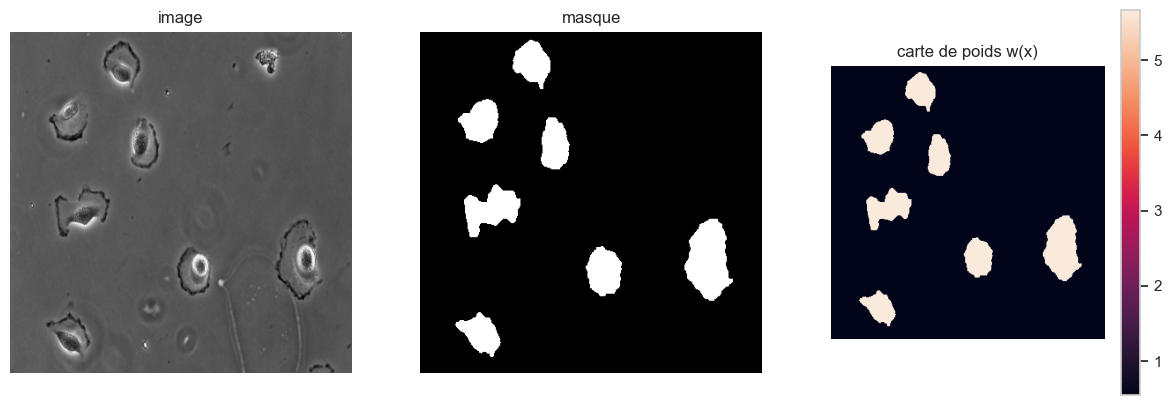

In [5]:
train_items = build_items(X_train, y_train)
val_items   = build_items(X_val, y_val)

# Val / test : images standardisées (mêmes statistiques d'entrée que le train)
X_val_s  = np.stack([s["img_p"] for s in val_items])[..., None]
X_test_s = np.stack([standardize(x) for x in X_test[..., 0]])[..., None]

# Aperçu de contrôle
s = train_items[0]
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(s["img_p"][PAD_SIZE:-PAD_SIZE, PAD_SIZE:-PAD_SIZE], cmap="gray"); ax[0].set_title("image")
ax[1].imshow(s["mask"], cmap="gray"); ax[1].set_title("masque")
im = ax[2].imshow(s["w"]); ax[2].set_title("carte de poids w(x)"); plt.colorbar(im, ax=ax[2])
for a in ax: a.axis("off")
plt.show()

### 2.3 Augmentation des données

In [6]:
def rotation(img, mask, w, rng):
    """Invariance aux rotations : rotation d'un multiple de 90° tiré aléatoirement.
    Entrées :
        img, mask, w : tuiles 572 x 572 (image, masque binaire, carte de poids)
        rng : générateur aléatoire NumPy
    Sorties :
        img, mask, w : tuiles 572 x 572 tournées du même angle
    """
    k = rng.integers(4)
    return tuple(np.rot90(a, k) for a in (img, mask, w))


def gray_value_variation(img, rng):
    """Variations de niveaux de gris : facteur et décalage aléatoires (transformation linéaire).
    Entrées :
        img : image 572 x 572 (standardisée)
        rng : générateur aléatoire NumPy
    Sorties :
        img : image 572 x 572, multipliée par un facteur dans [0,9 ; 1,1] puis décalée d'une valeur dans [-0,1 ; 0,1]
    """
    return img * rng.uniform(0.9, 1.1) + rng.uniform(-0.1, 0.1)


def augment(s, rng):
    """Applique toutes les augmentations : translation, rotation, variations de niveaux de gris.
    Entrées :
        s   : dict d'une image (voir translation)
        rng : générateur aléatoire NumPy
    Sorties :
        img, mask, w : tuiles 572 x 572 augmentées (le recadrage 388 x 388 est fait dans tile_generator)
    """
    img, mask, w = s["img_p"], s["mask_p"], s["w_p"]
    img, mask, w = rotation(img, mask, w, rng)
    img = gray_value_variation(img, rng)
    return img, mask, w

## 3. Définitions communes

In [7]:
def add_dice(s):
    return 2 * s["precision"] * s["recall"] / (s["precision"] + s["recall"] + 1e-8)

def dice_metric(y_true, y_pred):
    y_pred = (y_pred >= 0.5).astype(int)
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    dice = (2 * tp) / (2 * tp + fp + fn + 1e-8)

    return dice

def dice_loss(y_true, y_pred):
    """"Dice pour la classe d'intéret (index 1)"""
    y_true_fg = y_true[..., 1]
    y_pred_fg = y_pred[..., 1]
    intersection = K.sum(y_true_fg * y_pred_fg, axis=[1, 2])
    sum_true_pred = K.sum(y_true_fg, axis=[1, 2]) + K.sum(y_pred_fg, axis=[1, 2])
    dice = (2. * intersection + 1e-5) / (sum_true_pred + 1e-5)
    return 1.0 - K.mean(dice)

def focal_loss(y_true, y_pred, gamma=2.0, alpha=0.25):
    """Focal loss pour stabiliser l'apprentissage sur la classe minoritaire"""
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    focal = -y_true * (alpha * tf.pow(1.0 - y_pred, gamma) * tf.math.log(y_pred))
    return tf.reduce_mean(tf.reduce_sum(focal, axis=-1))

def combined_loss(y_true, y_pred):
    """Somme pondérée entre focal loss et la perte de Dice"""
    y_true_fg = y_true[..., 1]
    y_pred_fg = y_pred[..., 1]
    intersection = K.sum(y_true_fg * y_pred_fg, axis=[1, 2])
    sum_true_pred = K.sum(y_true_fg, axis=[1, 2]) + K.sum(y_pred_fg, axis=[1, 2])
    dice = (2. * intersection + 1e-5) / (sum_true_pred + 1e-5)
    dice_loss = 1.0 - K.mean(dice)
    f_loss = focal_loss(y_true, y_pred)
    return 0.1 * f_loss + 0.9 * dice_loss

## 4. U-Net
  Le but de ce projet est de développer un réseau de neurones appelé U-Net, dont la structure en forme de U lui donne son nom, et de comparer ses performances à celles de réseaux plus simples. Nous souhaitons déterminer si, dans le cadre de la segmentation d'images biomédicales, il est nécessaire de développer des architectures aussi complexes pour obtenir des performances satisfaisantes.

  Dans un premier temps, nous développerons le réseau U-Net, dont nous expliquerons la structure (encodeur, goulot d'étranglement, décodeur et skip connections) avant d'analyser ses performances. Nous en proposerons également une version simplifiée, plus compacte (trois niveaux de sous-échantillonnage, jusqu'à 512 filtres) et régularisée par des couches de BatchNormalization et de Dropout. Dans un second temps, nous développerons des solutions plus traditionnelles, telles qu'un réseau convolutionnel simple, un réseau ResNet et, enfin, un réseau simplifié inspiré d'architectures plus complexes, comme Inception.

  Nous analyserons ici des images de mammographie afin d'entraîner nos réseaux à segmenter les régions présentant des caractéristiques suspectes pouvant être associées à un cancer du sein. Contrairement à une simple classification, qui consiste à déterminer si une image contient ou non un cancer, la segmentation permet d'identifier et de délimiter précisément les zones suspectes au niveau des pixels, en labellisant les pixels plutôt que l'image dans son ensemble. Elle offre ainsi une information spatiale plus détaillée, permettant de localiser les anomalies au sein de l'image afin de simplifier le travail d'un spécialiste.

  Nous évaluerons les performances de nos modèles à l'aide de plusieurs métriques adaptées à la segmentation : la loss, l'accuracy, la precision, le recall, le score de Dice (ou F1 au niveau des pixels), l'IoU de la classe cancéreuse, le Mean IoU, ainsi que l'AUC ROC et l'AUC PR. L'accuracy seule étant trompeuse lorsque les pixels de fond sont très largement majoritaires, nous accorderons plus d'importance au Dice et à l'IoU, qui mesurent la qualité du recouvrement entre la zone prédite et la zone réelle, et à l'AUC PR, plus informative que l'AUC ROC lorsque la classe d'intérêt est minoritaire. Une attention particulière sera portée à la maximisation du recall, afin de limiter les faux négatifs, c'est-à-dire les régions cancéreuses qui ne seraient pas détectées par le modèle. Cet enjeu est particulièrement important dans le domaine médical, où l'absence de détection d'une anomalie peut avoir des conséquences significatives sur le diagnostic et la prise en charge des patientes. Ce recall devra néanmoins être mis en regard de la precision, afin de ne pas multiplier les fausses alertes qui alourdiraient le travail du spécialiste.

  Afin de garantir la reproductibilité des résultats et la comparabilité des modèles, une seed globale est fixée pour l'ensemble du notebook.

### 4.1 U-Net original

&nbsp;&nbsp;&nbsp;&nbsp; Le réseau U-Net est un réseau de neurones convolutif dont l'architecture repose sur deux parties complémentaires : un encodeur, qui réduit progressivement la résolution spatiale de l'image, et un décodeur, qui permet de reconstruire progressivement sa résolution initiale grâce à des convolutions transposées (up-convolutions).

&nbsp;&nbsp;&nbsp;&nbsp; L'encodeur est composé de quatre blocs successifs. Chacun de ces blocs contient deux couches de convolution de taille 3 × 3, suivies d'une fonction d'activation ReLU. À la fin de chaque bloc, une opération de max pooling de taille 2 × 2 est appliquée afin de réduire de moitié la résolution spatiale de l'image et d'extraire des caractéristiques de plus en plus abstraites.

&nbsp;&nbsp;&nbsp;&nbsp; Une particularité essentielle de l'architecture U-Net réside dans ses connexions de saut (skip connections). À la sortie de chaque bloc de l'encodeur, les caractéristiques extraites sont copiées puis recadrées (cropped) afin d'être transmises au bloc correspondant du décodeur. Ces connexions permettent de conserver les informations spatiales détaillées perdues lors de la réduction de résolution et de les réutiliser pendant la reconstruction.

&nbsp;&nbsp;&nbsp;&nbsp; Le bloc le plus profond du réseau, situé entre l'encodeur et le décodeur, constitue le point de transition de l'architecture. Il est composé de deux couches de convolution de taille 3 × 3, chacune suivie d'une fonction d'activation ReLU. Il permet d'extraire les caractéristiques les plus abstraites de l'image avant d'entamer la phase de reconstruction.

&nbsp;&nbsp;&nbsp;&nbsp; Le décodeur constitue la seconde partie du réseau. À chaque étage, la résolution spatiale est augmentée grâce à une convolution transposée (up-convolution) de taille 2 × 2. Les caractéristiques obtenues sont ensuite concaténées avec celles provenant de la connexion de saut correspondante de l'encodeur. Chaque bloc du décodeur est alors composé de deux couches de convolution de taille 3 × 3, suivies chacune d'une fonction d'activation ReLU.

&nbsp;&nbsp;&nbsp;&nbsp; Enfin, une dernière convolution 1 x 1 permet de projeter les caractéristiques obtenues sur le nombre de classes souhaité, afin d'attribuer à chaque pixel de l'image une classe et de produire ainsi la segmentation finale.

In [8]:
def conv_block(x, filters):
    """2 convolutions 3x3 + ReLU (valid) : enlève 4 pixels."""
    x = keras.layers.Conv2D(filters, 3, activation="relu", padding="valid")(x)
    x = keras.layers.Conv2D(filters, 3, activation="relu", padding="valid")(x)
    return x


def up_block(x, skip, filters, crop):
    """up-conv 2x2 -> crop du skip -> concat -> 2 convs 3x3."""
    x = keras.layers.Conv2DTranspose(filters, 2, strides=2)(x)
    skip = keras.layers.Cropping2D(crop)(skip)   # recadre le skip au centre
    x = keras.layers.Concatenate()([skip, x])
    return conv_block(x, filters)


def get_unet_original(input_shape=(572, 572, 1), num_classes=2):
    inputs = keras.Input(input_shape)                           # 572

    # Encodeur (x1..x4 gardés pour les skip connections)
    x1 = conv_block(inputs, 64)                                 # 568
    x2 = conv_block(keras.layers.MaxPooling2D(2)(x1), 128)      # 280
    x3 = conv_block(keras.layers.MaxPooling2D(2)(x2), 256)      # 136
    x4 = conv_block(keras.layers.MaxPooling2D(2)(x3), 512)      # 64

    # Bottleneck
    b = conv_block(keras.layers.MaxPooling2D(2)(x4), 1024)      # 28

    # Décodeur : crop = (taille du skip - taille après up-conv) / 2
    d4 = up_block(b,  x4, 512, crop=4)                          # 52
    d3 = up_block(d4, x3, 256, crop=16)                         # 100
    d2 = up_block(d3, x2, 128, crop=40)                         # 196
    d1 = up_block(d2, x1, 64,  crop=88)                         # 388

    outputs = keras.layers.Conv2D(num_classes, 1, activation="softmax")(d1)   # 388x388x2

    model = keras.Model(inputs, outputs, name="unet")
    return model


unet_original = get_unet_original()
unet_original.summary()

Model: "unet"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 572, 572, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 570, 570, 64  640         ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 conv2d_1 (Conv2D)              (None, 568, 568, 64  36928       ['conv2d[0][0]']                 
                                )                                                              

In [9]:
early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

y_train_unet_original = tf.one_hot(y_train[..., 0], depth=2)
y_val_unet_original = tf.one_hot(y_val[..., 0], depth=2)

N_EPOCHS = 30
BATCH_SIZE = 5

optimizer_unet_original = tf.keras.optimizers.Adam(learning_rate=5e-5)

unet_original.compile(
    optimizer=optimizer_unet_original,
    loss=combined_loss,
    metrics=[
        keras.metrics.CategoricalAccuracy(name="accuracy"),
        keras.metrics.Precision(class_id=1, name="precision"),
        keras.metrics.Recall(class_id=1, name="recall"),
        keras.metrics.AUC(name="auc"),
        keras.metrics.AUC(curve="PR", name="auc_pr"),
        keras.metrics.OneHotIoU(num_classes=2, target_class_ids=[1], name="iou_fg"),
        keras.metrics.OneHotMeanIoU(num_classes=2, name="mean_iou"),
    ],
)

history_unet_original = unet_original.fit(
    X_train,
    y_train_unet_original,
    epochs=N_EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val_unet_original),
    callbacks=[early_stopping],
)

Epoch 1/30
30/30 [==============================] - 21s 572ms/step - loss: 0.7989 - accuracy: 0.7594 - precision: 0.1579 - recall: 0.6011 - auc: 0.5051 - auc_pr: 0.5075 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.7993 - val_accuracy: 0.4428 - val_precision: 0.1058 - val_recall: 0.9993 - val_auc: 0.5151 - val_auc_pr: 0.5183 - val_iou_fg: 0.3333 - val_mean_iou: 0.3333
Epoch 2/30
30/30 [==============================] - 16s 522ms/step - loss: 0.7946 - accuracy: 0.8404 - precision: 0.2942 - recall: 0.9949 - auc: 0.7725 - auc_pr: 0.7396 - iou_fg: 0.3448 - mean_iou: 0.3448 - val_loss: 0.7807 - val_accuracy: 0.9152 - val_precision: 0.4366 - val_recall: 0.9856 - val_auc: 0.8848 - val_auc_pr: 0.8197 - val_iou_fg: 0.3333 - val_mean_iou: 0.3333
Epoch 3/30
30/30 [==============================] - 15s 506ms/step - loss: 0.6851 - accuracy: 0.8933 - precision: 0.3782 - recall: 0.9309 - auc: 0.8680 - auc_pr: 0.8169 - iou_fg: 0.3659 - mean_iou: 0.3659 - val_loss: 0.3154 - val_accuracy: 0.9599 - v

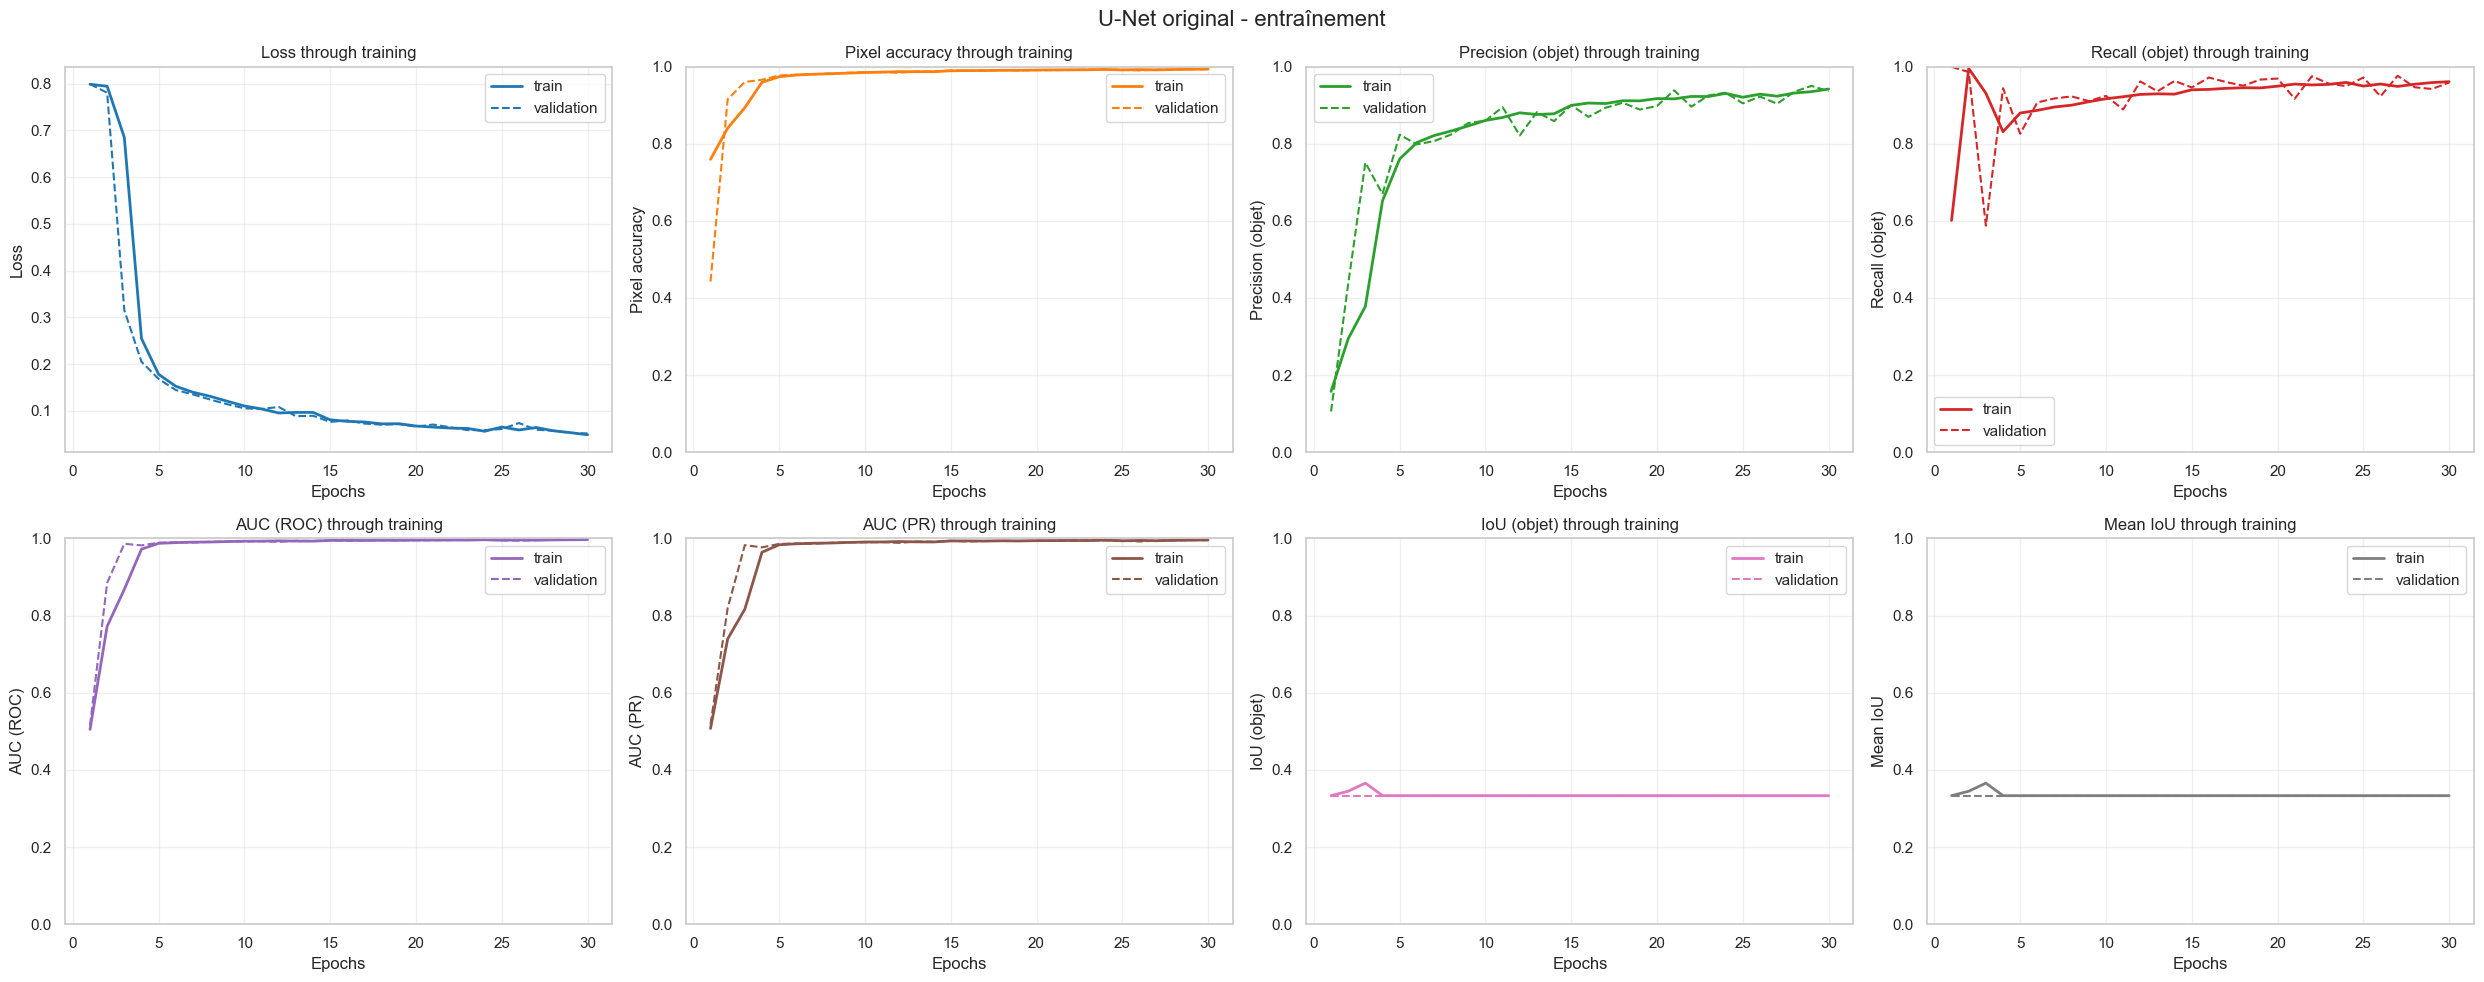

In [10]:
history_df_unet_original = pd.DataFrame(history_unet_original.history)
epochs = range(1, len(history_df_unet_original) + 1)  # robuste si early stopping

metrics = [
    "loss", "accuracy", "precision", "recall",
    "auc", "auc_pr", "iou_fg", "mean_iou",
]
titles = {
    "loss": "Loss",
    "accuracy": "Pixel accuracy",
    "precision": "Precision (objet)",
    "recall": "Recall (objet)",
    "auc": "AUC (ROC)",
    "auc_pr": "AUC (PR)",
    "iou_fg": "IoU (objet)",
    "mean_iou": "Mean IoU",
}

figure, axes = plt.subplots(2, 4, figsize=(25, 10))
palette = sns.color_palette("tab10", n_colors=len(metrics))

for index, (metric_name, axis) in enumerate(zip(metrics, axes.flat)):
    if metric_name not in history_df_unet_original.columns:
        axis.set_visible(False)  # métrique absente de l'historique
        continue

    color = palette[index]
    axis.plot(epochs, history_df_unet_original[metric_name], lw=2, color=color, label="train")
    if "val_" + metric_name in history_df_unet_original.columns:
        axis.plot(epochs, history_df_unet_original["val_" + metric_name], ls="--", color=color, label="validation")

    if metric_name != "loss":
        axis.set_ylim(0, 1)
    axis.set_ylabel(titles[metric_name])
    axis.set_xlabel("Epochs")
    axis.set_title("%s through training" % titles[metric_name])
    axis.grid(alpha=0.3)
    axis.legend()

plt.suptitle("U-Net original - entraînement", fontsize=16)
plt.tight_layout()
plt.show()

In [11]:
display(history_df_unet_original)

,loss,accuracy,precision,recall,auc,auc_pr,iou_fg,mean_iou,val_loss,val_accuracy,val_precision,val_recall,val_auc,val_auc_pr,val_iou_fg,val_mean_iou
0,0.798855,0.759393,0.157871,0.601114,0.505148,0.507528,0.333333,0.333333,0.799349,0.442825,0.105788,0.999284,0.515090,0.518333,0.333333,0.333333
1,0.794573,0.840398,0.294230,0.994914,0.772464,0.739623,0.344828,0.344828,0.780660,0.915151,0.436560,0.985623,0.884763,0.819650,0.333333,0.333333
2,0.685123,0.893272,0.378241,0.930876,0.868033,0.816887,0.365854,0.365854,0.315443,0.959942,0.750955,0.587488,0.986193,0.982680,0.333333,0.333333
3,0.255094,0.959117,0.651946,0.831026,0.972207,0.964308,0.333333,0.333333,0.205331,0.965587,0.669680,0.943740,0.982020,0.976933,0.333333,0.333333
4,0.178352,0.973450,0.760282,0.879430,0.987259,0.983616,0.333333,0.333333,0.168563,0.976815,0.823208,0.825832,0.989060,0.985900,0.333333,0.333333
5,0.152903,0.977900,0.802936,0.886376,0.989271,0.986159,0.333333,0.333333,0.144867,0.978737,0.798174,0.906952,0.989867,0.986929,0.333333,0.333333
6,0.140053,0.979968,0.820936,0.895047,0.990445,0.987664,0.333333,0.333333,0.135531,0.980032,0.806591,0.917181,0.989290,0.986145,0.333333,0.333333
7,0.131425,0.981260,0.832846,0.899775,0.990805,0.988112,0.333333,0.333333,0.124485,0.981872,0.823784,0.922473,0.991351,0.988820,0.333333,0.333333
8,0.120865,0.982869,0.846014,0.908693,0.992015,0.989675,0.333333,0.333333,0.114492,0.983781,0.853504,0.910344,0.992297,0.990031,0.333333,0.333333
9,0.110716,0.984482,0.860155,0.916468,0.992859,0.990759,0.333333,0.333333,0.105741,0.985020,0.859563,0.923807,0.992362,0.990099,0.333333,0.333333


In [12]:
y_test_unet_original = tf.one_hot(y_test[..., 0], depth=2)
score_unet_original = unet_original.evaluate(X_test, y_test_unet_original, batch_size=BATCH_SIZE, return_dict=True)

# Dice (= F1 pixel) déduit de la précision et du recall de la classe objet
dice_unet_original = 2 * score_unet_original["precision"] * score_unet_original["recall"] / (score_unet_original["precision"] + score_unet_original["recall"] + 1e-8)

df_score_unet_original = pd.DataFrame(
    {
        "Métrique": [
            "Loss",
            "Accuracy",
            "Precision (objet)",
            "Recall (objet)",
            "Dice / F1 (objet)",
            "IoU (objet)",
            "Mean IoU",
            "AUC (ROC)",
            "AUC (PR)",
        ],
        "Valeur": [
            score_unet_original["loss"],
            score_unet_original["accuracy"],
            score_unet_original["precision"],
            score_unet_original["recall"],
            dice_unet_original,
            score_unet_original["iou_fg"],
            score_unet_original["mean_iou"],
            score_unet_original["auc"],
            score_unet_original["auc_pr"],
        ],
    }
).set_index("Métrique")

display(df_score_unet_original.style.format("{:.4f}"))

10/10 [==============================] - 1s 141ms/step - loss: 0.0543 - accuracy: 0.9927 - precision: 0.9339 - recall: 0.9565 - auc: 0.9964 - auc_pr: 0.9954 - iou_fg: 0.3333 - mean_iou: 0.3333


,Valeur
Métrique,
Loss,0.0543
Accuracy,0.9927
Precision (objet),0.9339
Recall (objet),0.9565
Dice / F1 (objet),0.9450
IoU (objet),0.3333
Mean IoU,0.3333
AUC (ROC),0.9964
AUC (PR),0.9954


### 4.2 U-Net simplifié

&nbsp;&nbsp;&nbsp;&nbsp; Le réseau U-Net simplifié est un réseau de neurones convolutif qui repose grandement sur le U-Net mais dans lequel nous avons essayer de réduire le nombre de neurones en passant de 31 millions à un peu moins de 8 millions.

&nbsp;&nbsp;&nbsp;&nbsp; L'encodeur est composé de trois blocs successifs contenant chacun deux couches de convolution de taille 3 × 3, avec une activation SiLU. Chaque bloc est suivi d'une normalisation par lot (Batch Normalization) et d'une couche de Dropout de taux 0,2. Entre les blocs, une opération de max pooling de taille 2 × 2 réduit de moitié la résolution spatiale. Le nombre de filtres augmente progressivement : 64, 128 puis 256.

&nbsp;&nbsp;&nbsp;&nbsp; Le bottleneck, situé entre l'encodeur et le décodeur, constitue le niveau le plus profond du réseau. Il reprend la même structure de convolution avec 512 filtres et permet d'extraire des caractéristiques plus abstraites de l'image.

&nbsp;&nbsp;&nbsp;&nbsp; Le décodeur est composé de trois blocs. À chaque étape, une convolution transposée de taille 2 × 2 augmente la résolution spatiale. Les caractéristiques obtenues sont ensuite concaténées avec celles issues du bloc correspondant de l'encodeur, après un recadrage (cropping) permettant d'adapter leurs dimensions. Ces connexions de saut permettent de récupérer les informations spatiales perdues lors de la réduction de résolution et d'améliorer la précision de la segmentation.

&nbsp;&nbsp;&nbsp;&nbsp; Enfin, une convolution de taille 1 × 1 avec une activation Softmax permet de produire une carte de segmentation en deux classes. Un recadrage final ajuste les dimensions de la sortie à 388 × 388 pixels.

&nbsp;&nbsp;&nbsp;&nbsp; Par rapport à un U-Net classique, notre architecture est simplifiée puisqu'elle comporte trois niveaux d'encodage et trois niveaux de décodage, au lieu des quatre niveaux. Elle conserve néanmoins le principe fondamental du U-Net, à savoir les connexions de saut entre l'encodeur et le décodeur. Elle se distingue également par l'utilisation de la fonction d'activation SiLU et de couches de Dropout avec un taux de 0,2 afin de limiter le surapprentissage.

In [13]:
def conv_block(x, filters):
    x = keras.layers.Conv2D(
        filters, 3, activation="silu", padding="valid"
    )(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Dropout(0.2)(x)
    x = keras.layers.Conv2D(
        filters, 3, activation="silu", padding="valid"
    )(x)

    return x


def up_block(x, skip, filters, crop):
    x = keras.layers.Conv2DTranspose(
        filters, 2, strides=2, padding="valid"
    )(x)

    skip = keras.layers.Cropping2D(
        cropping=((crop, crop), (crop, crop))
    )(skip)

    x = keras.layers.Concatenate()([skip, x])

    return conv_block(x, filters)


def get_model_2(input_shape=(572, 572, 1), num_classes=2):

    inputs = keras.Input(shape=input_shape)  # 572 x 572 x 1

    # Encodeur
    x1 = conv_block(inputs, 64)  # 568 x 568
    x2 = conv_block(
        keras.layers.MaxPooling2D(2)(x1), 128
    )  # 280 x 280

    x3 = conv_block(
        keras.layers.MaxPooling2D(2)(x2), 256
    )  # 136 x 136

    # Bottleneck
    b = conv_block(
        keras.layers.MaxPooling2D(2)(x3), 512
    )  # 64 x 64

    # Décodeur
    d3 = up_block(b, x3, 256, crop=4)    # 124 x 124
    d2 = up_block(d3, x2, 128, crop=16)  # 244 x 244
    d1 = up_block(d2, x1, 64, crop=40)   # 484 x 484

    # Recadrage final : 484 -> 388
    d1 = keras.layers.Cropping2D(
        cropping=((48, 48), (48, 48))
    )(d1)  # 388 x 388

    # Couche de segmentation : 2 classes
    outputs = keras.layers.Conv2D(
        num_classes, 1, activation="softmax", padding="valid"
    )(d1)  # 388 x 388 x 2

    model_unet_simplified = keras.Model(
        inputs, outputs, name="unet_simplified"
    )

    return model_unet_simplified


unet_simplified = get_model_2()
unet_simplified.summary()

Model: "unet_simplified"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_2 (InputLayer)           [(None, 572, 572, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv2d_19 (Conv2D)             (None, 570, 570, 64  640         ['input_2[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization (BatchNorm  (None, 570, 570, 64  256        ['conv2d_19[0][0]']              
 alization)                     )                                                   

In [14]:
early_stopping_unet_simplified = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

N_EPOCHS = 30
BATCH_SIZE = 5

y_train_unet_simplified = tf.one_hot(y_train[..., 0], depth=2)
y_val_unet_simplified = tf.one_hot(y_val[..., 0], depth=2)

optimizer_unet_simplified = tf.keras.optimizers.Adam(learning_rate=1e-4)

unet_simplified.compile(
    optimizer=optimizer_unet_simplified,
    loss=combined_loss,
    metrics=[
        keras.metrics.CategoricalAccuracy(name="accuracy"),
        keras.metrics.Precision(class_id=1, name="precision"),
        keras.metrics.Recall(class_id=1, name="recall"),
        keras.metrics.AUC(name="auc"),
        keras.metrics.AUC(curve="PR", name="auc_pr"),
        keras.metrics.OneHotIoU(num_classes=2, target_class_ids=[1], name="iou_fg"),
        keras.metrics.OneHotMeanIoU(num_classes=2, name="mean_iou"),
    ],
)

history_unet_simplified = unet_simplified.fit(
    X_train,
    y_train_unet_simplified,
    epochs=N_EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val_unet_simplified),
    callbacks=[early_stopping_unet_simplified],
)

Epoch 1/30
30/30 [==============================] - 33s 884ms/step - loss: 0.5174 - accuracy: 0.8897 - precision: 0.3733 - recall: 0.9611 - auc: 0.8834 - auc_pr: 0.8203 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.8023 - val_accuracy: 0.9340 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_auc: 0.9449 - val_auc_pr: 0.9198 - val_iou_fg: 0.0000e+00 - val_mean_iou: 0.2500
Epoch 2/30
30/30 [==============================] - 26s 858ms/step - loss: 0.1715 - accuracy: 0.9792 - precision: 0.7880 - recall: 0.9412 - auc: 0.9784 - auc_pr: 0.9709 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.8305 - val_accuracy: 0.9340 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_auc: 0.9378 - val_auc_pr: 0.9185 - val_iou_fg: 0.0000e+00 - val_mean_iou: 0.2500
Epoch 3/30
30/30 [==============================] - 25s 847ms/step - loss: 0.1018 - accuracy: 0.9864 - precision: 0.8697 - recall: 0.9361 - auc: 0.9905 - auc_pr: 0.9877 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.8623 - 

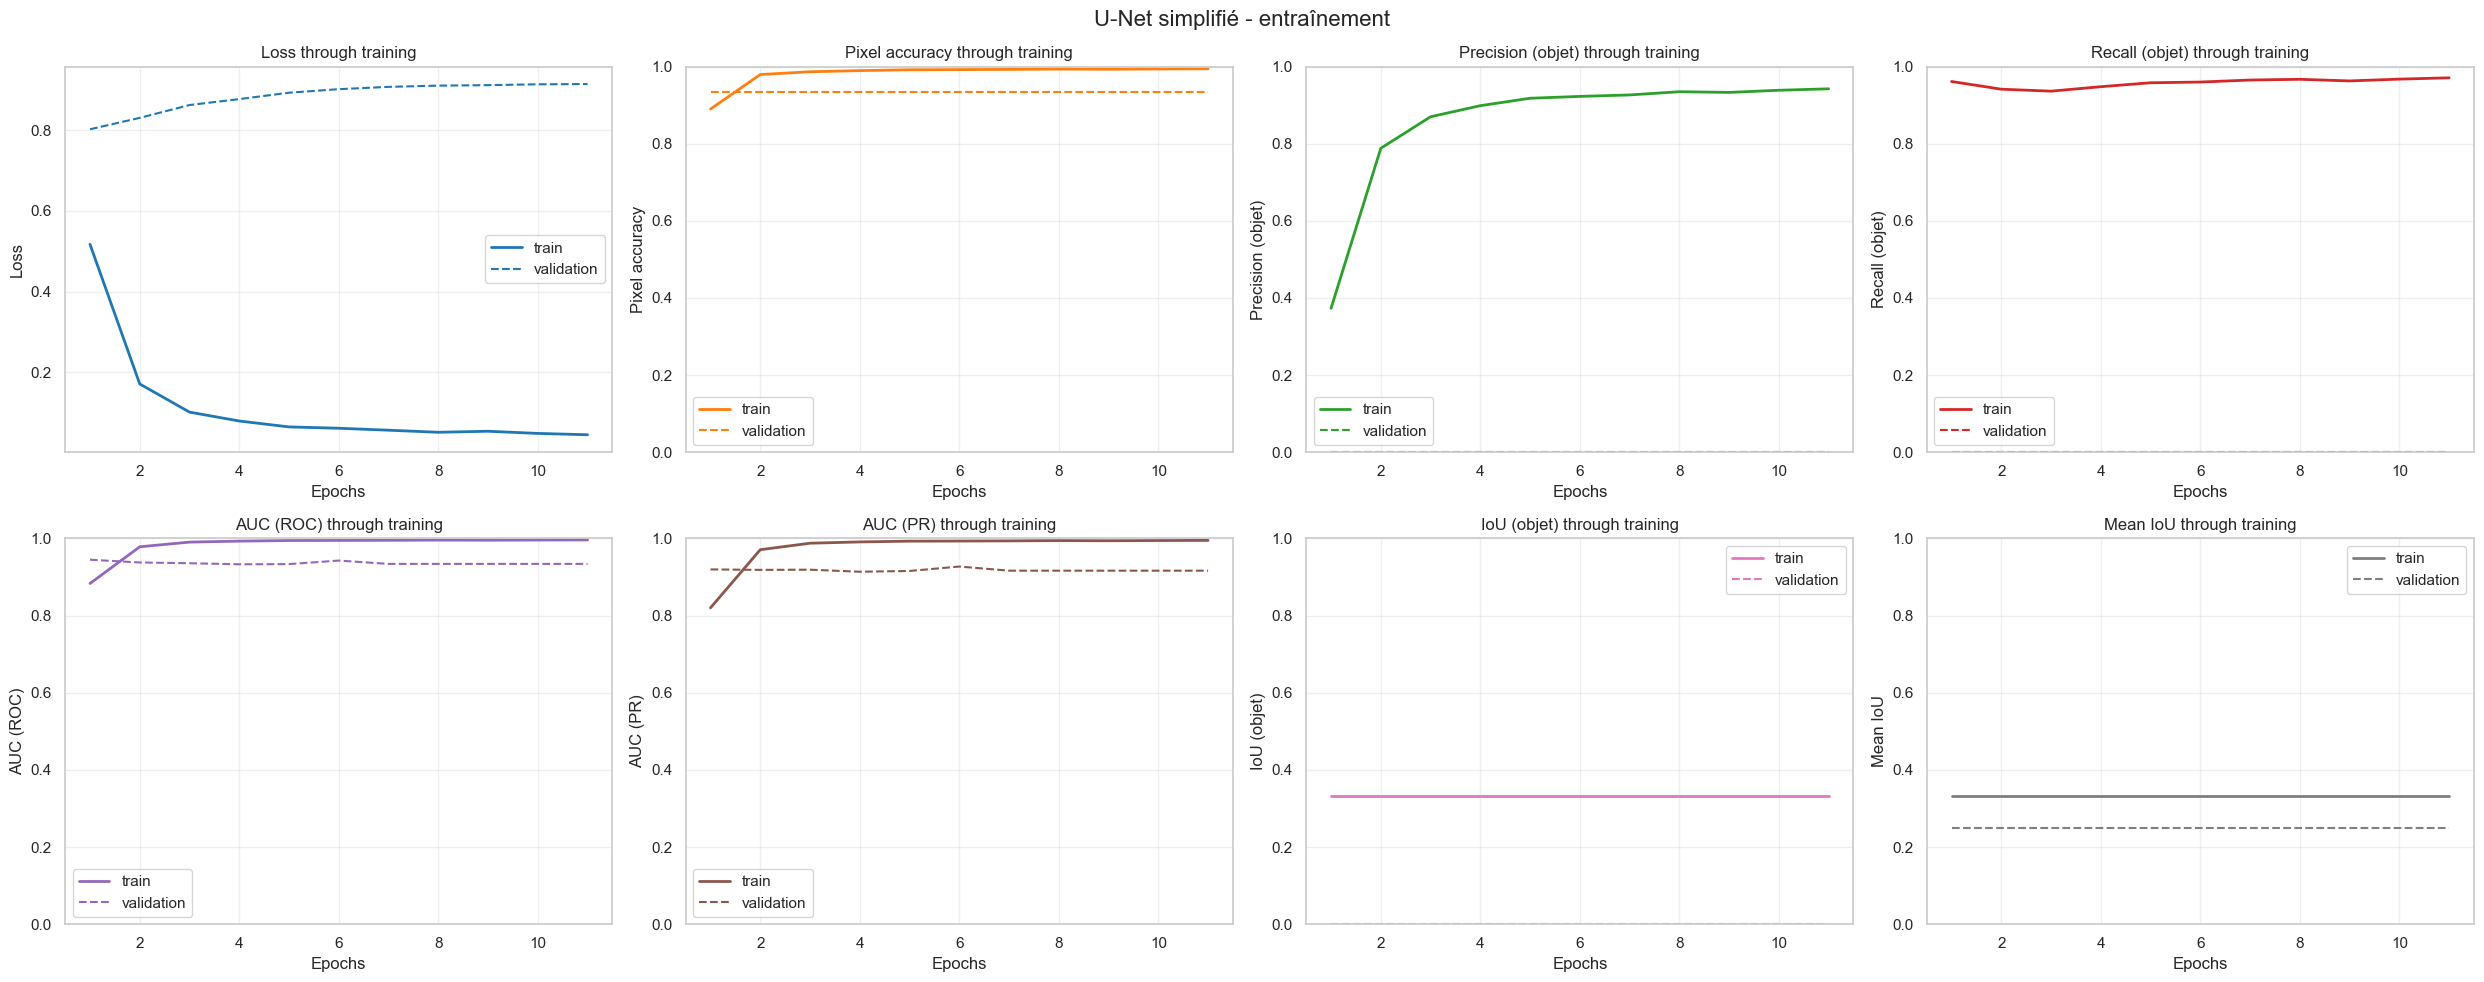

In [15]:
history_df_unet_simplified = pd.DataFrame(history_unet_simplified.history)
epochs = range(1, len(history_df_unet_simplified) + 1)  # robuste si early stopping

metrics = [
    "loss", "accuracy", "precision", "recall",
    "auc", "auc_pr", "iou_fg", "mean_iou",
]
titles = {
    "loss": "Loss",
    "accuracy": "Pixel accuracy",
    "precision": "Precision (objet)",
    "recall": "Recall (objet)",
    "auc": "AUC (ROC)",
    "auc_pr": "AUC (PR)",
    "iou_fg": "IoU (objet)",
    "mean_iou": "Mean IoU",
}

figure, axes = plt.subplots(2, 4, figsize=(25, 10))
palette = sns.color_palette("tab10", n_colors=len(metrics))

for index, (metric_name, axis) in enumerate(zip(metrics, axes.flat)):
    if metric_name not in history_df_unet_simplified.columns:
        axis.set_visible(False)  # métrique absente de l'historique
        continue

    color = palette[index]
    axis.plot(epochs, history_df_unet_simplified[metric_name], lw=2, color=color, label="train")
    if "val_" + metric_name in history_df_unet_simplified.columns:
        axis.plot(epochs, history_df_unet_simplified["val_" + metric_name], ls="--", color=color, label="validation")

    if metric_name != "loss":
        axis.set_ylim(0, 1)
    axis.set_ylabel(titles[metric_name])
    axis.set_xlabel("Epochs")
    axis.set_title("%s through training" % titles[metric_name])
    axis.grid(alpha=0.3)
    axis.legend()

plt.suptitle("U-Net simplifié - entraînement", fontsize=16)
plt.tight_layout()
plt.show()

In [16]:
display(history_df_unet_simplified)

,loss,accuracy,precision,recall,auc,auc_pr,iou_fg,mean_iou,val_loss,val_accuracy,val_precision,val_recall,val_auc,val_auc_pr,val_iou_fg,val_mean_iou
0,0.517391,0.889731,0.373309,0.961149,0.883356,0.820283,0.333333,0.333333,0.802314,0.934044,0.0,0.0,0.944876,0.919804,0.0,0.25
1,0.171463,0.979178,0.788015,0.941163,0.978413,0.970851,0.333333,0.333333,0.830534,0.934044,0.0,0.0,0.937751,0.918532,0.0,0.25
2,0.101750,0.986380,0.869738,0.936106,0.990522,0.987683,0.333333,0.333333,0.862308,0.934044,0.0,0.0,0.935788,0.919042,0.0,0.25
3,0.079708,0.989361,0.898477,0.947661,0.993094,0.991016,0.333333,0.333333,0.876989,0.934044,0.0,0.0,0.933072,0.913769,0.0,0.25
4,0.065135,0.991455,0.917689,0.957866,0.994619,0.992994,0.333333,0.333333,0.892850,0.934044,0.0,0.0,0.933557,0.915735,0.0,0.25
5,0.061804,0.991931,0.922507,0.959702,0.994855,0.993299,0.333333,0.333333,0.901585,0.934044,0.0,0.0,0.942653,0.927205,0.0,0.25
6,0.056972,0.992536,0.926288,0.964939,0.995181,0.993722,0.333333,0.333333,0.907334,0.934044,0.0,0.0,0.934044,0.916476,0.0,0.25
7,0.051853,0.993274,0.934637,0.966824,0.995767,0.994484,0.333333,0.333333,0.910344,0.934044,0.0,0.0,0.934044,0.916476,0.0,0.25
8,0.054396,0.992884,0.932873,0.962641,0.995444,0.994064,0.333333,0.333333,0.911547,0.934044,0.0,0.0,0.934044,0.916476,0.0,0.25
9,0.049006,0.993580,0.938408,0.967276,0.995875,0.994623,0.333333,0.333333,0.913631,0.934044,0.0,0.0,0.934044,0.916476,0.0,0.25


In [17]:
y_test_unet_simplified = tf.one_hot(y_test[..., 0], depth=2)
score_unet_simplified = unet_simplified.evaluate(X_test, y_test_unet_simplified, batch_size=BATCH_SIZE, return_dict=True)

# Dice (= F1 pixel) déduit de la précision et du recall de la classe objet
dice_unet_simplified = 2 * score_unet_simplified["precision"] * score_unet_simplified["recall"] / (score_unet_simplified["precision"] + score_unet_simplified["recall"] + 1e-8)

df_score_unet_simplified = pd.DataFrame(
    {
        "Métrique": [
            "Loss",
            "Accuracy",
            "Precision (objet)",
            "Recall (objet)",
            "Dice / F1 (objet)",
            "IoU (objet)",
            "Mean IoU",
            "AUC (ROC)",
            "AUC (PR)",
        ],
        "Valeur": [
            score_unet_simplified["loss"],
            score_unet_simplified["accuracy"],
            score_unet_simplified["precision"],
            score_unet_simplified["recall"],
            dice_unet_simplified,
            score_unet_simplified["iou_fg"],
            score_unet_simplified["mean_iou"],
            score_unet_simplified["auc"],
            score_unet_simplified["auc_pr"],
        ],
    }
).set_index("Métrique")

display(df_score_unet_simplified.style.format("{:.4f}"))

10/10 [==============================] - 2s 224ms/step - loss: 0.8032 - accuracy: 0.9346 - precision: 0.0000e+00 - recall: 0.0000e+00 - auc: 0.9446 - auc_pr: 0.9193 - iou_fg: 0.0000e+00 - mean_iou: 0.2500


,Valeur
Métrique,
Loss,0.8032
Accuracy,0.9346
Precision (objet),0.0000
Recall (objet),0.0000
Dice / F1 (objet),0.0000
IoU (objet),0.0000
Mean IoU,0.2500
AUC (ROC),0.9446
AUC (PR),0.9193


### 4.3 U-Net avec padding

In [18]:
def conv_block(x, filters):
    """2 convolutions 3x3 + ReLU (same) : conserve la taille spatiale."""
    x = keras.layers.Conv2D(filters, 3, activation="relu", padding="same")(x)
    x = keras.layers.Conv2D(filters, 3, activation="relu", padding="same")(x)
    return x


def up_block(x, skip, filters):
    """up-conv 2x2 -> concat -> 2 convs 3x3."""
    x = keras.layers.Conv2DTranspose(filters, 2, strides=2, padding="same")(x)
    target_size = (skip.shape[1], skip.shape[2])
    x = keras.layers.Resizing(target_size[0], target_size[1])(x)
    x = keras.layers.Concatenate()([skip, x])
    return conv_block(x, filters)


def get_unet_padding(input_shape=(572, 572, 1), num_classes=2):   # remplacer 3 par 1 si image en niveau de gris
    inputs = keras.Input(shape=input_shape)                           # 512x512   input size doit être multiple de 2 sinon probleme

    # Encodeur (x1..x4 gardés pour les skip connections)
    x1 = conv_block(inputs, 32)                                 # 512x512
    x2 = conv_block(keras.layers.MaxPooling2D(2)(x1), 64)      # 256x256
    x3 = conv_block(keras.layers.MaxPooling2D(2)(x2), 128)      # 128x128
    x4 = conv_block(keras.layers.MaxPooling2D(2)(x3), 256)      # 64x64

    # Bottleneck
    b = conv_block(keras.layers.MaxPooling2D(2)(x4), 512)      # 32x32

    # Décodeur
    d4 = up_block(b,  x4, 256)                                  # 64x64
    d3 = up_block(d4, x3, 128)                                  # 128x128
    d2 = up_block(d3, x2, 64)                                  # 256x256
    d1 = up_block(d2, x1, 32)                                   # 512x512

    d1 = keras.layers.Resizing(input_shape[0], input_shape[1])(d1)
    d1 = keras.layers.Cropping2D(((92, 92), (92, 92)))(d1)

    # Sortie : 388 x 388 avec 2 canaux (1 par classe)
    outputs = keras.layers.Conv2D(num_classes, 1, activation="softmax")(d1)

    model = keras.Model(inputs, outputs, name="unet_padding")
    return model

unet_padding = get_unet_padding()
unet_padding.summary()

Model: "unet_padding"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_3 (InputLayer)           [(None, 572, 572, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv2d_34 (Conv2D)             (None, 572, 572, 32  320         ['input_3[0][0]']                
                                )                                                                 
                                                                                                  
 conv2d_35 (Conv2D)             (None, 572, 572, 32  9248        ['conv2d_34[0][0]']              
                                )                                                      

In [19]:
early_stopping_unet_padding = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

y_train_unet_padding = tf.one_hot(y_train[..., 0], depth=2)
y_val_unet_padding = tf.one_hot(y_val[..., 0], depth=2)

optimizer_unet_padding = tf.keras.optimizers.Adam(learning_rate=5e-5)
unet_padding.compile(
    optimizer=optimizer_unet_padding,
    loss=combined_loss,
    metrics=[
        keras.metrics.CategoricalAccuracy(name="accuracy"),
        keras.metrics.Precision(class_id=1, name="precision"),
        keras.metrics.Recall(class_id=1, name="recall"),
        keras.metrics.AUC(name="auc"),
        keras.metrics.AUC(curve="PR", name="auc_pr"),
        keras.metrics.OneHotIoU(num_classes=2, target_class_ids=[1], name="iou_fg"),
        keras.metrics.OneHotMeanIoU(num_classes=2, name="mean_iou"),
    ],
)

history_unet_padding = unet_padding.fit(
    X_train,
    y_train_unet_padding,
    epochs=N_EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val_unet_padding),
    callbacks=[early_stopping_unet_padding],
)

Epoch 1/30
30/30 [==============================] - 13s 355ms/step - loss: 0.7990 - accuracy: 0.7985 - precision: 0.1160 - recall: 0.3051 - auc: 0.8195 - auc_pr: 0.8133 - iou_fg: 0.3409 - mean_iou: 0.3409 - val_loss: 0.7998 - val_accuracy: 0.4903 - val_precision: 0.1064 - val_recall: 0.9090 - val_auc: 0.3484 - val_auc_pr: 0.3989 - val_iou_fg: 0.3333 - val_mean_iou: 0.3333
Epoch 2/30
30/30 [==============================] - 9s 314ms/step - loss: 0.7985 - accuracy: 0.2451 - precision: 0.0796 - recall: 0.9767 - auc: 0.2037 - auc_pr: 0.3544 - iou_fg: 0.3409 - mean_iou: 0.2889 - val_loss: 0.7988 - val_accuracy: 0.0660 - val_precision: 0.0660 - val_recall: 0.9999 - val_auc: 0.1128 - val_auc_pr: 0.3486 - val_iou_fg: 0.4444 - val_mean_iou: 0.2677
Epoch 3/30
30/30 [==============================] - 10s 318ms/step - loss: 0.7934 - accuracy: 0.5498 - precision: 0.1280 - recall: 0.9892 - auc: 0.6622 - auc_pr: 0.6672 - iou_fg: 0.3448 - mean_iou: 0.3206 - val_loss: 0.7806 - val_accuracy: 0.9009 - va

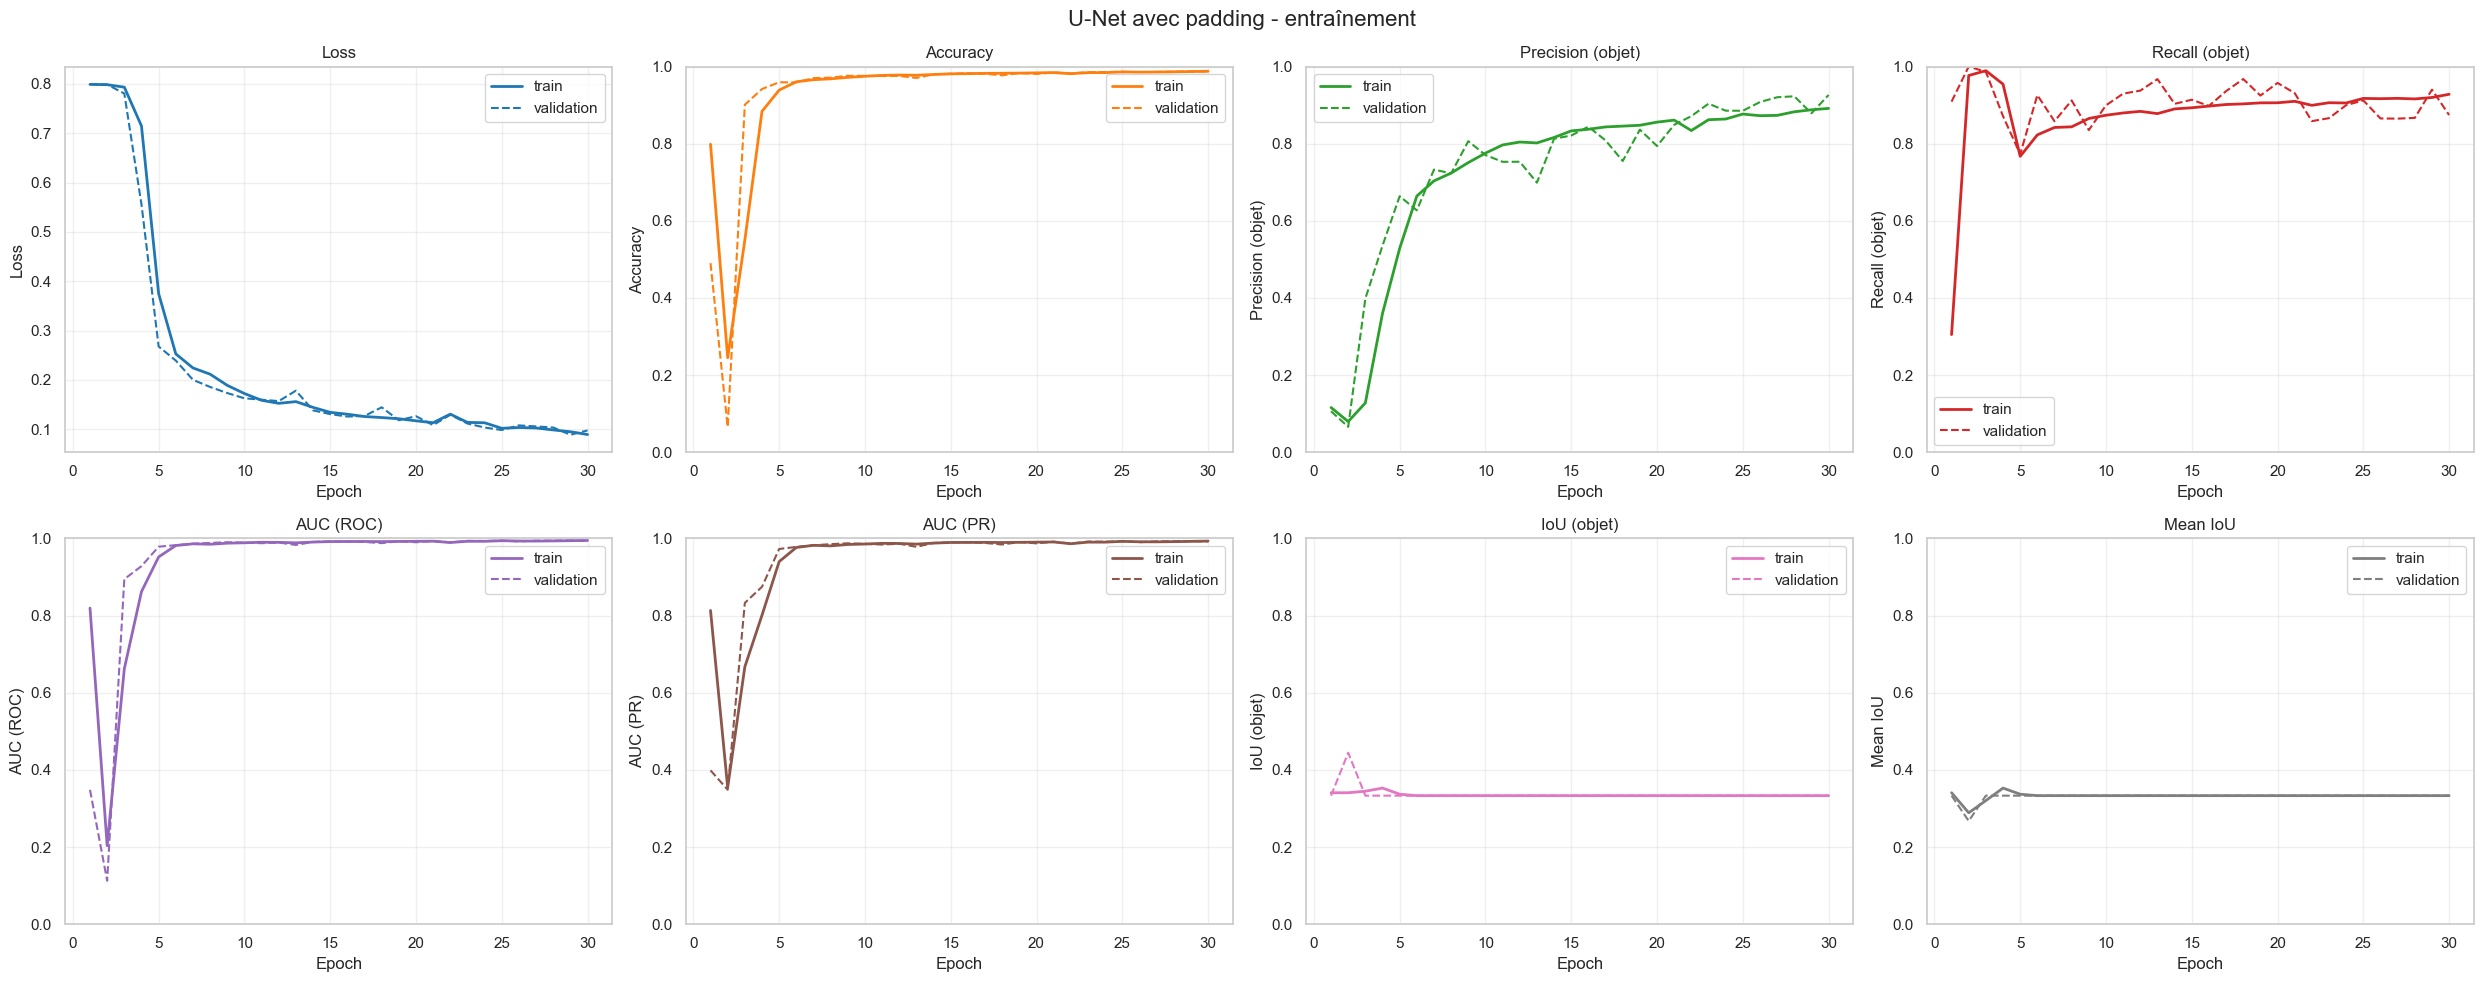

In [20]:
history_df_unet_padding = pd.DataFrame(history_unet_padding.history)
epochs = range(1, len(history_df_unet_padding) + 1)

metrics = [
    "loss", "accuracy", "precision", "recall",
    "auc", "auc_pr", "iou_fg", "mean_iou",
]
titles = {
    "loss": "Loss",
    "accuracy": "Accuracy",
    "precision": "Precision (objet)",
    "recall": "Recall (objet)",
    "auc": "AUC (ROC)",
    "auc_pr": "AUC (PR)",
    "iou_fg": "IoU (objet)",
    "mean_iou": "Mean IoU",
}

figure, axes = plt.subplots(2, 4, figsize=(25, 10))
palette = sns.color_palette("tab10", n_colors=len(metrics))

for index, (metric_name, axis) in enumerate(zip(metrics, axes.flat)):
    if metric_name not in history_df_unet_padding.columns:
        axis.set_visible(False)
        continue
    color = palette[index]
    axis.plot(epochs, history_df_unet_padding[metric_name], lw=2, color=color, label="train")
    validation_metric = "val_" + metric_name
    if validation_metric in history_df_unet_padding.columns:
        axis.plot(epochs, history_df_unet_padding[validation_metric], ls="--", color=color, label="validation")
    if metric_name != "loss":
        axis.set_ylim(0, 1)
    axis.set_ylabel(titles[metric_name])
    axis.set_xlabel("Epoch")
    axis.set_title(titles[metric_name])
    axis.grid(alpha=0.3)
    axis.legend()

plt.suptitle("U-Net avec padding - entraînement", fontsize=16)
plt.tight_layout()
plt.show()

In [21]:
display(history_df_unet_padding)

,loss,accuracy,precision,recall,auc,auc_pr,iou_fg,mean_iou,val_loss,val_accuracy,val_precision,val_recall,val_auc,val_auc_pr,val_iou_fg,val_mean_iou
0,0.799046,0.798529,0.116043,0.305105,0.819523,0.813348,0.340909,0.340909,0.799792,0.490293,0.106366,0.909007,0.348395,0.398888,0.333333,0.333333
1,0.798483,0.245050,0.079623,0.976665,0.203674,0.354407,0.340909,0.288876,0.798755,0.065952,0.065952,0.999943,0.112801,0.348608,0.444444,0.267677
2,0.793414,0.549767,0.128050,0.989195,0.662184,0.667245,0.344828,0.320562,0.780594,0.900945,0.398575,0.986050,0.894553,0.832929,0.333333,0.333333
3,0.714733,0.883774,0.360070,0.954194,0.862089,0.801063,0.352941,0.352941,0.555726,0.941702,0.535697,0.871156,0.928310,0.874793,0.333333,0.333333
4,0.375039,0.938821,0.528682,0.767178,0.952089,0.939934,0.337079,0.337079,0.267800,0.959192,0.663759,0.772721,0.978676,0.972732,0.333333,0.333333
5,0.252727,0.960424,0.664283,0.822755,0.981696,0.976691,0.333333,0.333333,0.239146,0.958814,0.627199,0.925878,0.982692,0.978081,0.333333,0.333333
6,0.224258,0.965774,0.703503,0.841999,0.986054,0.982269,0.333333,0.333333,0.200170,0.970000,0.732761,0.858101,0.986136,0.982228,0.333333,0.333333
7,0.211614,0.968074,0.723728,0.843651,0.984967,0.980738,0.333333,0.333333,0.185676,0.971145,0.722960,0.911988,0.988449,0.985260,0.333333,0.333333
8,0.188938,0.971859,0.750977,0.865217,0.987788,0.984359,0.333333,0.333333,0.173377,0.975910,0.806458,0.835190,0.990176,0.987398,0.333333,0.333333
9,0.172350,0.974683,0.775414,0.873680,0.988787,0.985596,0.333333,0.333333,0.162680,0.975695,0.770514,0.899358,0.989109,0.985994,0.333333,0.333333


In [22]:
y_test_unet_padding = tf.one_hot(y_test[..., 0], depth=2)
score_unet_padding = unet_padding.evaluate(
    X_test, y_test_unet_padding, batch_size=BATCH_SIZE, return_dict=True
)

dice_unet_padding = 2 * score_unet_padding["precision"] * score_unet_padding["recall"] / (
    score_unet_padding["precision"] + score_unet_padding["recall"] + 1e-8
)

df_score_unet_padding = pd.DataFrame(
    {
        "Métrique": [
            "Loss", "Accuracy", "Precision (objet)", "Recall (objet)",
            "Dice / F1 (objet)", "IoU (objet)", "Mean IoU",
            "AUC (ROC)", "AUC (PR)",
        ],
        "Valeur": [
            score_unet_padding["loss"], score_unet_padding["accuracy"],
            score_unet_padding["precision"], score_unet_padding["recall"],
            dice_unet_padding, score_unet_padding["iou_fg"], score_unet_padding["mean_iou"],
            score_unet_padding["auc"], score_unet_padding["auc_pr"],
        ],
    }
).set_index("Métrique")

display(df_score_unet_padding.style.format("{:.4f}"))

10/10 [==============================] - 1s 105ms/step - loss: 0.1022 - accuracy: 0.9868 - precision: 0.9269 - recall: 0.8664 - auc: 0.9943 - auc_pr: 0.9926 - iou_fg: 0.3333 - mean_iou: 0.3333


,Valeur
Métrique,
Loss,0.1022
Accuracy,0.9868
Precision (objet),0.9269
Recall (objet),0.8664
Dice / F1 (objet),0.8956
IoU (objet),0.3333
Mean IoU,0.3333
AUC (ROC),0.9943
AUC (PR),0.9926


### 4.4 U-Net avec ASPP

In [23]:
def get_unet_aspp(input_shape=(572, 572, 1), num_classes=2):
    inputs = keras.Input(shape=input_shape)

    def aspp_conv_block(tensor, filters):
        tensor = keras.layers.Conv2D(filters, 3, activation="relu", padding="same")(tensor)
        tensor = keras.layers.BatchNormalization()(tensor)
        return tensor

    x1 = aspp_conv_block(inputs, 32)
    x2 = aspp_conv_block(keras.layers.MaxPooling2D(2)(x1), 64)
    x3 = aspp_conv_block(keras.layers.MaxPooling2D(2)(x2), 128)
    x4 = aspp_conv_block(keras.layers.MaxPooling2D(2)(x3), 256)

    bottleneck = aspp_conv_block(keras.layers.MaxPooling2D(2)(x4), 512)

    u4 = keras.layers.Conv2DTranspose(256, 2, strides=2, padding="same")(bottleneck)
    u4 = keras.layers.Resizing(x4.shape[1], x4.shape[2])(u4)
    u4 = keras.layers.Concatenate()([u4, x4])
    u4 = aspp_conv_block(u4, 256)

    u3 = keras.layers.Conv2DTranspose(128, 2, strides=2, padding="same")(u4)
    u3 = keras.layers.Resizing(x3.shape[1], x3.shape[2])(u3)
    u3 = keras.layers.Concatenate()([u3, x3])
    u3 = aspp_conv_block(u3, 128)

    u2 = keras.layers.Conv2DTranspose(64, 2, strides=2, padding="same")(u3)
    u2 = keras.layers.Resizing(x2.shape[1], x2.shape[2])(u2)
    u2 = keras.layers.Concatenate()([u2, x2])
    u2 = aspp_conv_block(u2, 64)

    u1 = keras.layers.Conv2DTranspose(32, 2, strides=2, padding="same")(u2)
    u1 = keras.layers.Resizing(x1.shape[1], x1.shape[2])(u1)
    u1 = keras.layers.Concatenate()([u1, x1])
    u1 = aspp_conv_block(u1, 32)

    u1 = keras.layers.Cropping2D(((92, 92), (92, 92)))(u1)
    outputs = keras.layers.Conv2D(num_classes, 1, activation="softmax")(u1)
    return keras.Model(inputs, outputs, name="unet_aspp")


unet_aspp = get_unet_aspp()
unet_aspp.summary()

Model: "unet_aspp"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_4 (InputLayer)           [(None, 572, 572, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv2d_53 (Conv2D)             (None, 572, 572, 32  320         ['input_4[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization_7 (BatchNo  (None, 572, 572, 32  128        ['conv2d_53[0][0]']              
 rmalization)                   )                                                         

In [24]:
early_stopping_unet_aspp = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

y_train_unet_aspp = tf.one_hot(y_train[..., 0], depth=2)
y_val_unet_aspp = tf.one_hot(y_val[..., 0], depth=2)

optimizer_unet_aspp = tf.keras.optimizers.Adam(learning_rate=1e-4)
unet_aspp.compile(
    optimizer=optimizer_unet_aspp,
    loss=combined_loss,
    metrics=[
        keras.metrics.CategoricalAccuracy(name="accuracy"),
        keras.metrics.Precision(class_id=1, name="precision"),
        keras.metrics.Recall(class_id=1, name="recall"),
        keras.metrics.AUC(name="auc"),
        keras.metrics.AUC(curve="PR", name="auc_pr"),
        keras.metrics.OneHotIoU(num_classes=2, target_class_ids=[1], name="iou_fg"),
        keras.metrics.OneHotMeanIoU(num_classes=2, name="mean_iou"),
    ],
)

history_unet_aspp = unet_aspp.fit(
    X_train,
    y_train_unet_aspp,
    epochs=N_EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val_unet_aspp),
    callbacks=[early_stopping_unet_aspp],
)

Epoch 1/30
30/30 [==============================] - 11s 299ms/step - loss: 0.6824 - accuracy: 0.6885 - precision: 0.1555 - recall: 0.8278 - auc: 0.7552 - auc_pr: 0.7208 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.7991 - val_accuracy: 0.9353 - val_precision: 0.6157 - val_recall: 0.0493 - val_auc: 0.9485 - val_auc_pr: 0.9393 - val_iou_fg: 0.3333 - val_mean_iou: 0.3333
Epoch 2/30
30/30 [==============================] - 8s 265ms/step - loss: 0.2803 - accuracy: 0.9609 - precision: 0.6383 - recall: 0.9541 - auc: 0.9742 - auc_pr: 0.9640 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.8220 - val_accuracy: 0.9340 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_auc: 0.9350 - val_auc_pr: 0.9175 - val_iou_fg: 0.0000e+00 - val_mean_iou: 0.2500
Epoch 3/30
30/30 [==============================] - 8s 258ms/step - loss: 0.1247 - accuracy: 0.9860 - precision: 0.8611 - recall: 0.9416 - auc: 0.9946 - auc_pr: 0.9930 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.8634 - val_accuracy: 

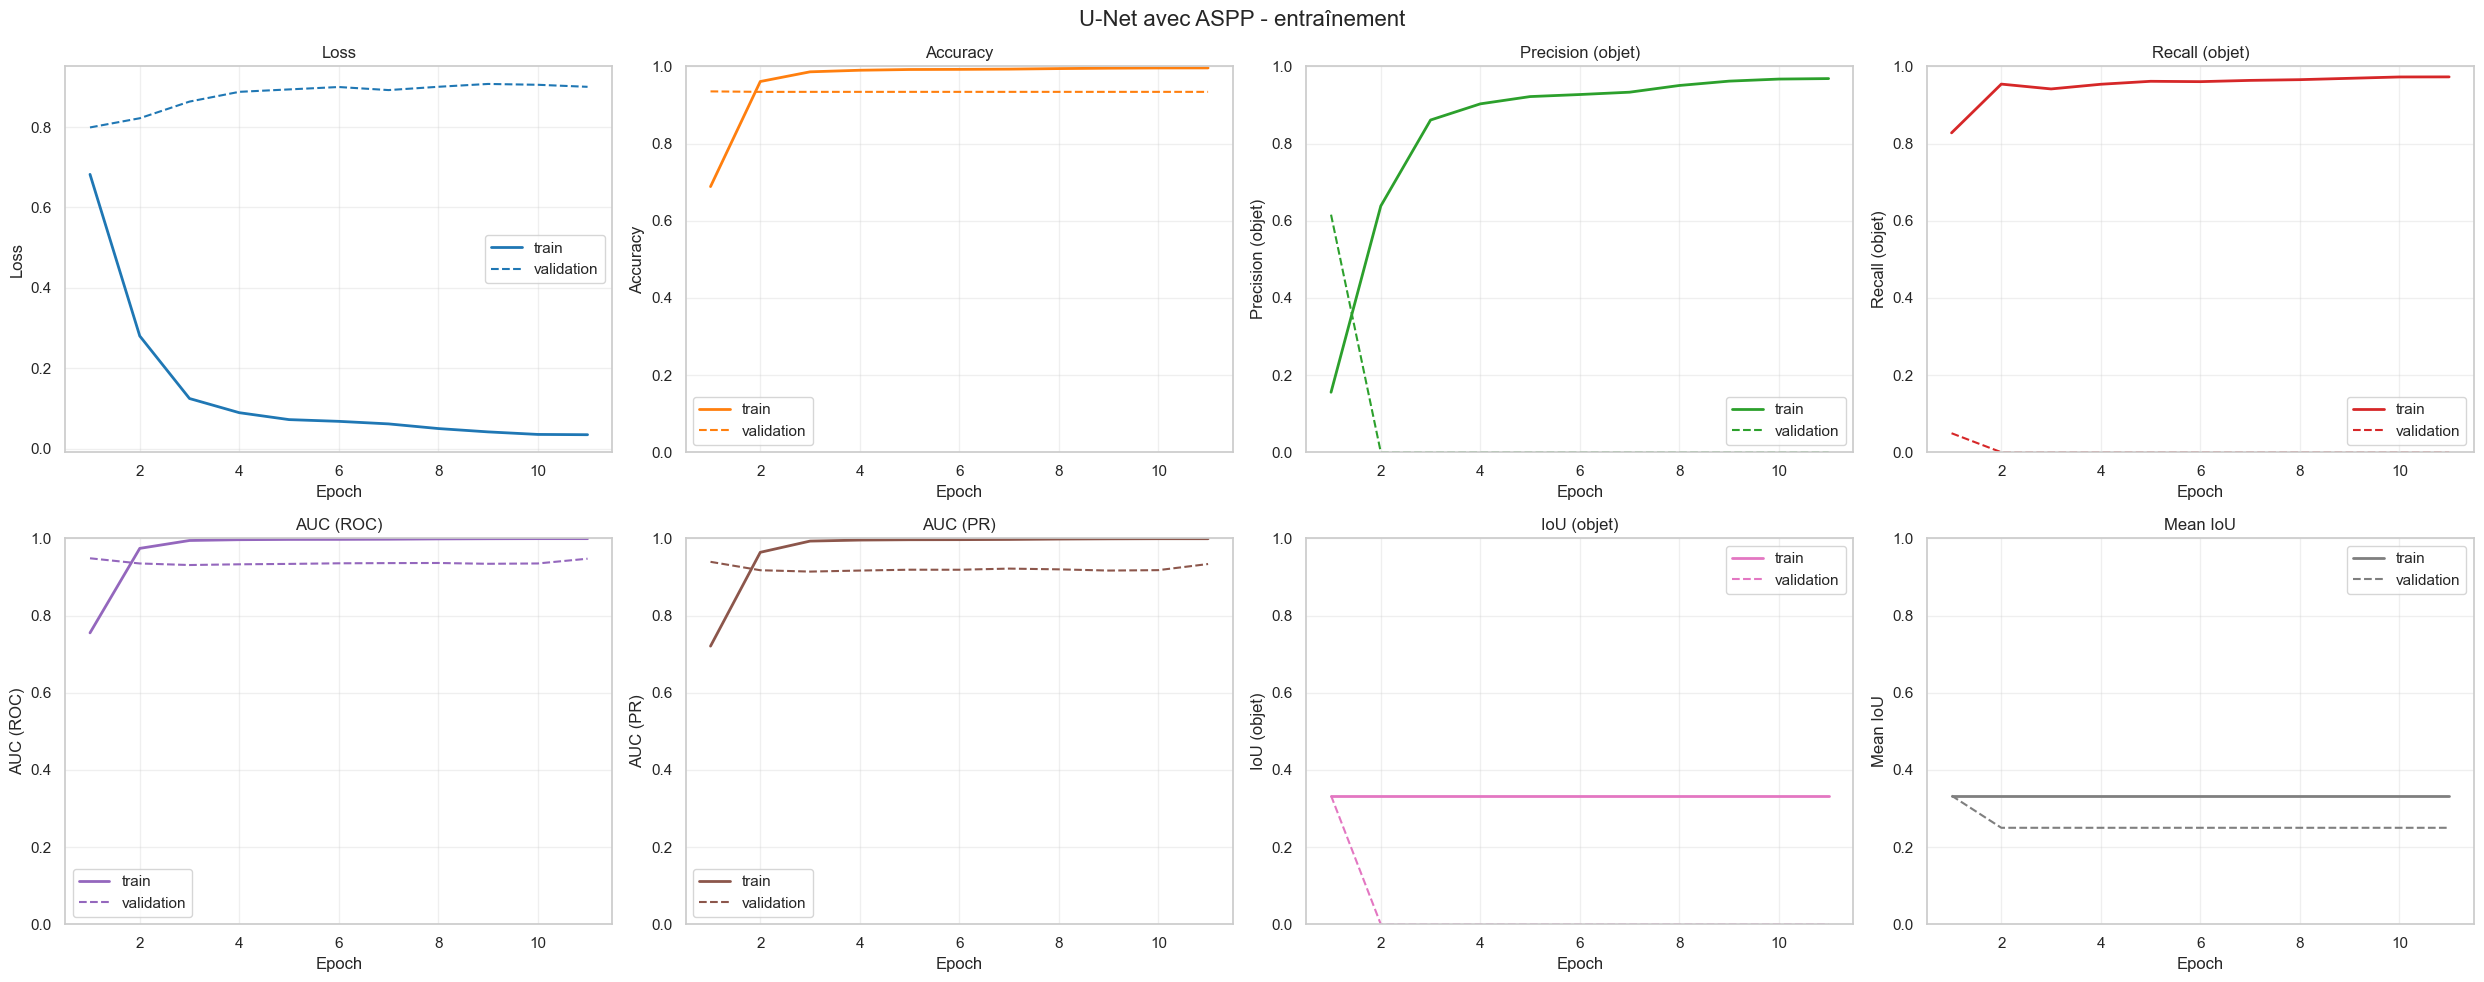

In [25]:
history_df_unet_aspp = pd.DataFrame(history_unet_aspp.history)
epochs = range(1, len(history_df_unet_aspp) + 1)

metrics = [
    "loss", "accuracy", "precision", "recall",
    "auc", "auc_pr", "iou_fg", "mean_iou",
]
titles = {
    "loss": "Loss",
    "accuracy": "Accuracy",
    "precision": "Precision (objet)",
    "recall": "Recall (objet)",
    "auc": "AUC (ROC)",
    "auc_pr": "AUC (PR)",
    "iou_fg": "IoU (objet)",
    "mean_iou": "Mean IoU",
}

figure, axes = plt.subplots(2, 4, figsize=(25, 10))
palette = sns.color_palette("tab10", n_colors=len(metrics))

for index, (metric_name, axis) in enumerate(zip(metrics, axes.flat)):
    if metric_name not in history_df_unet_aspp.columns:
        axis.set_visible(False)
        continue
    color = palette[index]
    axis.plot(epochs, history_df_unet_aspp[metric_name], lw=2, color=color, label="train")
    validation_metric = "val_" + metric_name
    if validation_metric in history_df_unet_aspp.columns:
        axis.plot(epochs, history_df_unet_aspp[validation_metric], ls="--", color=color, label="validation")
    if metric_name != "loss":
        axis.set_ylim(0, 1)
    axis.set_ylabel(titles[metric_name])
    axis.set_xlabel("Epoch")
    axis.set_title(titles[metric_name])
    axis.grid(alpha=0.3)
    axis.legend()

plt.suptitle("U-Net avec ASPP - entraînement", fontsize=16)
plt.tight_layout()
plt.show()

In [26]:
display(history_df_unet_aspp)

,loss,accuracy,precision,recall,auc,auc_pr,iou_fg,mean_iou,val_loss,val_accuracy,val_precision,val_recall,val_auc,val_auc_pr,val_iou_fg,val_mean_iou
0,0.682354,0.688505,0.155502,0.827784,0.755176,0.720813,0.333333,0.333333,0.799076,0.935266,0.615709,0.049268,0.948499,0.939304,0.333333,0.333333
1,0.280275,0.960853,0.638261,0.954146,0.974175,0.963958,0.333333,0.333333,0.821957,0.934044,0.000000,0.000000,0.935040,0.917538,0.000000,0.250000
2,0.124702,0.985964,0.861051,0.941616,0.994599,0.993048,0.333333,0.333333,0.863397,0.934044,0.000000,0.000000,0.931017,0.914026,0.000000,0.250000
3,0.089443,0.990072,0.902949,0.953747,0.996669,0.995710,0.333333,0.333333,0.887657,0.934044,0.000000,0.000000,0.932901,0.916692,0.000000,0.250000
4,0.072238,0.991983,0.921797,0.961429,0.997367,0.996597,0.333333,0.333333,0.893676,0.934044,0.000000,0.000000,0.933917,0.918880,0.000000,0.250000
5,0.067917,0.992326,0.927140,0.960491,0.997515,0.996787,0.333333,0.333333,0.899647,0.934044,0.000000,0.000000,0.935486,0.918782,0.000000,0.250000
6,0.061577,0.992977,0.933181,0.963762,0.997914,0.997302,0.333333,0.333333,0.892014,0.934044,0.000000,0.000000,0.936001,0.921738,0.000000,0.250000
7,0.049987,0.994357,0.950576,0.965652,0.998679,0.998294,0.333333,0.333333,0.900228,0.934044,0.000000,0.000000,0.936313,0.919807,0.000000,0.250000
8,0.041691,0.995376,0.961848,0.969159,0.999133,0.998882,0.333333,0.333333,0.907270,0.934044,0.000000,0.000000,0.934223,0.916697,0.000000,0.250000
9,0.035368,0.995973,0.967195,0.972651,0.999384,0.999206,0.333333,0.333333,0.905212,0.934044,0.000000,0.000000,0.935061,0.917754,0.000000,0.250000


In [27]:
y_test_unet_aspp = tf.one_hot(y_test[..., 0], depth=2)
score_unet_aspp = unet_aspp.evaluate(
    X_test, y_test_unet_aspp, batch_size=BATCH_SIZE, return_dict=True
)

dice_unet_aspp = 2 * score_unet_aspp["precision"] * score_unet_aspp["recall"] / (
    score_unet_aspp["precision"] + score_unet_aspp["recall"] + 1e-8
)

df_score_unet_aspp = pd.DataFrame(
    {
        "Métrique": [
            "Loss", "Accuracy", "Precision (objet)", "Recall (objet)",
            "Dice / F1 (objet)", "IoU (objet)", "Mean IoU",
            "AUC (ROC)", "AUC (PR)",
        ],
        "Valeur": [
            score_unet_aspp["loss"], score_unet_aspp["accuracy"],
            score_unet_aspp["precision"], score_unet_aspp["recall"],
            dice_unet_aspp, score_unet_aspp["iou_fg"], score_unet_aspp["mean_iou"],
            score_unet_aspp["auc"], score_unet_aspp["auc_pr"],
        ],
    }
).set_index("Métrique")

display(df_score_unet_aspp.style.format("{:.4f}"))

10/10 [==============================] - 1s 113ms/step - loss: 0.8000 - accuracy: 0.9355 - precision: 0.5942 - recall: 0.0444 - auc: 0.9483 - auc_pr: 0.9388 - iou_fg: 0.3333 - mean_iou: 0.3333


,Valeur
Métrique,
Loss,0.8000
Accuracy,0.9355
Precision (objet),0.5942
Recall (objet),0.0444
Dice / F1 (objet),0.0826
IoU (objet),0.3333
Mean IoU,0.3333
AUC (ROC),0.9483
AUC (PR),0.9388


## 5. ResNet

### 5.1 ResNet-50

&nbsp;&nbsp;&nbsp;&nbsp; Le réseau ResNet50_Segmentation est un réseau de neurones convolutif destiné à la segmentation d'images. Il s'inspire de l'architecture ResNet-50 et repose sur des blocs résiduels (bottleneck blocks), qui permettent de faciliter l'apprentissage des réseaux profonds grâce à des connexions de raccourci (shortcut connections).

&nbsp;&nbsp;&nbsp;&nbsp; Le réseau commence par une convolution de taille 7 × 7 avec 64 filtres et un pas de 2, suivie d'une opération de max pooling de taille 3 × 3. Cette première étape permet de réduire la résolution spatiale de l'image tout en extrayant les premières caractéristiques.

&nbsp;&nbsp;&nbsp;&nbsp; L'extraction des caractéristiques repose ensuite sur quatre groupes de blocs résiduels contenant respectivement 3, 4, 6 et 3 blocs. Chaque bloc est composé de trois convolutions successives de tailles 1 × 1, 3 × 3 et 1 × 1. Des couches de Batch Normalization et de Dropout (0,2) sont intégrées après les convolutions afin de stabiliser l'apprentissage et de limiter le surapprentissage. Les connexions résiduelles permettent quant à elles de transmettre directement les informations d'entrée vers la sortie de chaque bloc.

&nbsp;&nbsp;&nbsp;&nbsp; Contrairement à la ResNet-50 originale, qui se termine par une couche de classification, notre architecture intègre une tête de segmentation. Celle-ci est composée d'une convolution 3 × 3 avec 256 filtres, suivie d'une convolution transposée (Conv2DTranspose) de taille 4 × 4 avec 128 filtres et un pas de 4, permettant d'augmenter la résolution spatiale. Enfin, une convolution 1 × 1 avec une activation Softmax produit une carte de segmentation en deux classes, redimensionnée à 388 × 388 pixels.

&nbsp;&nbsp;&nbsp;&nbsp; La principale différence entre ResNet-50 et notre architecture réside donc dans leur objectif final. ResNet-50 est initialement conçue pour la classification d'images et utilise une couche de pooling global suivie d'une couche dense pour prédire une classe. Notre modèle conserve la structure résiduelle de ResNet-50, mais remplace cette partie de classification par un décodeur simplifié permettant d'effectuer une segmentation pixel par pixel. De plus, nous avons ajouté des couches de Dropout avec un taux de 0,2 dans les blocs résiduels afin de limiter le surapprentissage.

In [28]:
def bottleneck_block(x, filters, stride=1):
    shortcut = x

    x = keras.layers.Conv2D(filters, 1, strides=stride, padding="same", use_bias=False)(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Dropout(0.2)(x)
    x = keras.layers.Activation("relu")(x)

    x = keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Dropout(0.2)(x)
    x = keras.layers.Activation("relu")(x)

    x = keras.layers.Conv2D(filters * 4, 1, padding="same", use_bias=False)(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Dropout(0.2)(x)

    if stride != 1 or shortcut.shape[-1] != filters * 4:
        shortcut = keras.layers.Conv2D(filters * 4, 1, strides=stride,
                                        padding="same", use_bias=False)(shortcut)
        shortcut = keras.layers.BatchNormalization()(shortcut)

    x = keras.layers.Add()([x, shortcut])
    return keras.layers.Activation("relu")(x)


def get_resnet50(input_shape=(572, 572, 1), num_classes=2):
    inputs = keras.layers.Input(shape=input_shape)

    # Encodeur ResNet-50 avec sauvegarde des activations intermédiaires pour les skips
    # Niveau 1 (Input resolution / 2)
    x1 = keras.layers.Conv2D(64, 7, strides=2, padding="same", use_bias=False)(inputs)
    x1 = keras.layers.BatchNormalization()(x1)
    x1 = keras.layers.Activation("relu")(x1) # 286x286

    # Niveau 2 (Input resolution / 4)
    x2 = keras.layers.MaxPooling2D(3, strides=2, padding="same")(x1) # 143x143
    x2 = bottleneck_block(x2, 64)
    x2 = bottleneck_block(x2, 64)
    x2 = bottleneck_block(x2, 64)

    # Niveau 3 (Input resolution / 8)
    x3 = bottleneck_block(x2, 128, stride=2) # 72x72
    x3 = bottleneck_block(x3, 128)
    x3 = bottleneck_block(x3, 128)
    x3 = bottleneck_block(x3, 128)

    # Niveau 4 (Input resolution / 16)
    x4 = bottleneck_block(x3, 256, stride=2) # 36x36
    x4 = bottleneck_block(x4, 256)
    x4 = bottleneck_block(x4, 256)
    x4 = bottleneck_block(x4, 256)
    x4 = bottleneck_block(x4, 256)
    x4 = bottleneck_block(x4, 256)

    # Bottleneck le plus profond (Input resolution / 32)
    b = bottleneck_block(x4, 512, stride=2) # 18x18
    b = bottleneck_block(b, 512)
    b = bottleneck_block(b, 512)

    # DECODEUR PROGRESSIF avec connexions de saut (Skip Connections)
    # Étape 1 : 18x18 -> 36x36
    u1 = keras.layers.Conv2DTranspose(256, 2, strides=2, padding="same")(b)
    u1 = keras.layers.Concatenate()([u1, x4])
    u1 = keras.layers.Conv2D(256, 3, padding="same", activation="relu")(u1)

    # Étape 2 : 36x36 -> 72x72
    u2 = keras.layers.Conv2DTranspose(128, 2, strides=2, padding="same")(u1)
    u2 = keras.layers.Concatenate()([u2, x3])
    u2 = keras.layers.Conv2D(128, 3, padding="same", activation="relu")(u2)

    # Étape 3 : 72x72 -> 143x143 -> Resizing à 143x143 si nécessaire
    u3 = keras.layers.Conv2DTranspose(64, 2, strides=2, padding="same")(u2)
    u3 = keras.layers.Resizing(143, 143)(u3)
    u3 = keras.layers.Concatenate()([u3, x2])
    u3 = keras.layers.Conv2D(64, 3, padding="same", activation="relu")(u3)

    # Étape 4 : Redimensionnement final vers la sortie cible 388x388
    u4 = keras.layers.Conv2DTranspose(32, 2, strides=2, padding="same")(u3)
    u4 = keras.layers.Resizing(388, 388)(u4)

    outputs = keras.layers.Conv2D(num_classes, 1, activation="softmax")(u4)

    model_resnet50 = keras.Model(inputs, outputs, name="resnet50")
    return model_resnet50

resnet50 = get_resnet50()
resnet50.summary()

Model: "resnet50"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_5 (InputLayer)           [(None, 572, 572, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv2d_63 (Conv2D)             (None, 286, 286, 64  3136        ['input_5[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization_16 (BatchN  (None, 286, 286, 64  256        ['conv2d_63[0][0]']              
 ormalization)                  )                                                          

In [29]:
early_stopping_resnet50 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

N_EPOCHS = 30
BATCH_SIZE = 5

y_train_resnet50 = tf.one_hot(y_train[..., 0], depth=2)
y_val_resnet50 = tf.one_hot(y_val[..., 0], depth=2)

optimizer_resnet50 = tf.keras.optimizers.Adam(learning_rate=1e-4)

resnet50.compile(
    optimizer=optimizer_resnet50,
    loss=combined_loss,
    metrics=[
            keras.metrics.CategoricalAccuracy(name="accuracy"),
            keras.metrics.Precision(class_id=1, name="precision"),
            keras.metrics.Recall(class_id=1, name="recall"),
            keras.metrics.AUC(name="auc"),
            keras.metrics.AUC(curve="PR", name="auc_pr"),
            keras.metrics.OneHotIoU(num_classes=2, target_class_ids=[1], name="iou_fg"),
            keras.metrics.OneHotMeanIoU(num_classes=2, name="mean_iou"),
    ],
)

history_resnet50 = resnet50.fit(
    X_train,
    y_train_resnet50,
    epochs=N_EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val_resnet50),
    callbacks=[early_stopping_resnet50],
)

Epoch 1/30
30/30 [==============================] - 12s 298ms/step - loss: 0.7662 - accuracy: 0.6833 - precision: 0.1160 - recall: 0.5657 - auc: 0.7313 - auc_pr: 0.7148 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.8068 - val_accuracy: 0.9340 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_auc: 0.9293 - val_auc_pr: 0.9103 - val_iou_fg: 0.0000e+00 - val_mean_iou: 0.2500
Epoch 2/30
30/30 [==============================] - 7s 237ms/step - loss: 0.6298 - accuracy: 0.8606 - precision: 0.2432 - recall: 0.5152 - auc: 0.9305 - auc_pr: 0.9186 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.8851 - val_accuracy: 0.9340 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_auc: 0.9266 - val_auc_pr: 0.9068 - val_iou_fg: 0.0000e+00 - val_mean_iou: 0.2500
Epoch 3/30
30/30 [==============================] - 7s 236ms/step - loss: 0.5492 - accuracy: 0.8970 - precision: 0.3341 - recall: 0.5477 - auc: 0.9473 - auc_pr: 0.9354 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.9053 - va

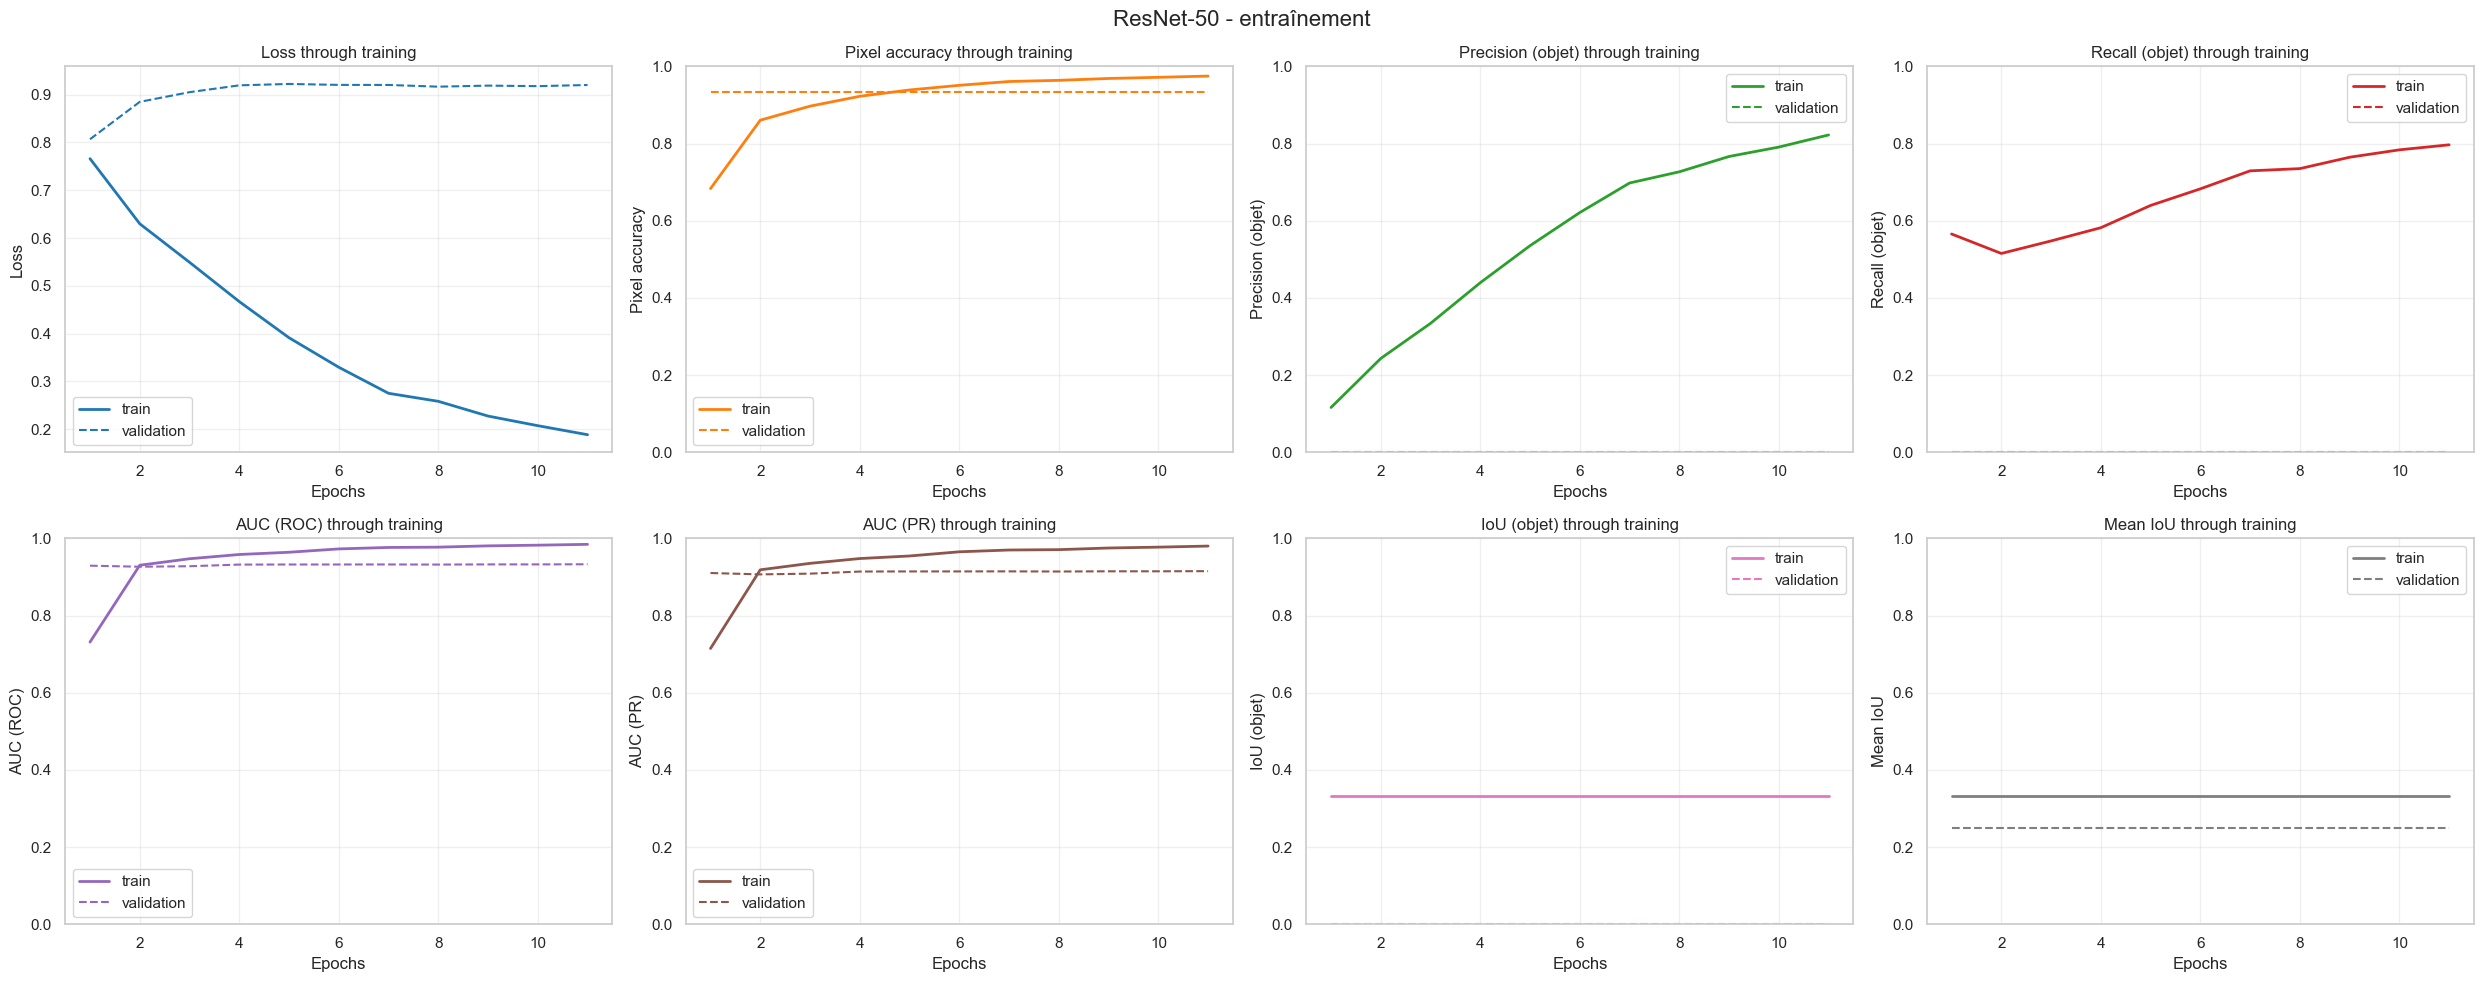

In [30]:
history_df_resnet50 = pd.DataFrame(history_resnet50.history)
epochs = range(1, len(history_df_resnet50) + 1)

metrics = [
    "loss", "accuracy", "precision", "recall",
    "auc", "auc_pr", "iou_fg", "mean_iou",
]
titles = {
    "loss": "Loss",
    "accuracy": "Pixel accuracy",
    "precision": "Precision (objet)",
    "recall": "Recall (objet)",
    "auc": "AUC (ROC)",
    "auc_pr": "AUC (PR)",
    "iou_fg": "IoU (objet)",
    "mean_iou": "Mean IoU",
}

figure, axes = plt.subplots(2, 4, figsize=(25, 10))
palette = sns.color_palette("tab10", n_colors=len(metrics))

for index, (metric_name, axis) in enumerate(zip(metrics, axes.flat)):
    if metric_name not in history_df_resnet50.columns:
        axis.set_visible(False)  # métrique absente de l'historique
        continue

    color = palette[index]
    axis.plot(epochs, history_df_resnet50[metric_name], lw=2, color=color, label="train")
    if "val_" + metric_name in history_df_resnet50.columns:
        axis.plot(epochs, history_df_resnet50["val_" + metric_name], ls="--", color=color, label="validation")

    if metric_name != "loss":
        axis.set_ylim(0, 1)
    axis.set_ylabel(titles[metric_name])
    axis.set_xlabel("Epochs")
    axis.set_title("%s through training" % titles[metric_name])
    axis.grid(alpha=0.3)
    axis.legend()

plt.suptitle("ResNet-50 - entraînement", fontsize=16)
plt.tight_layout()
plt.show()

In [31]:
display(history_df_resnet50)

,loss,accuracy,precision,recall,auc,auc_pr,iou_fg,mean_iou,val_loss,val_accuracy,val_precision,val_recall,val_auc,val_auc_pr,val_iou_fg,val_mean_iou
0,0.766164,0.683342,0.116003,0.565688,0.731344,0.714771,0.333333,0.333333,0.806794,0.934044,0.0,0.0,0.929333,0.910304,0.0,0.25
1,0.629811,0.860645,0.243177,0.515203,0.930459,0.918596,0.333333,0.333333,0.885054,0.934044,0.0,0.0,0.926611,0.906775,0.0,0.25
2,0.549203,0.896974,0.334117,0.547692,0.947296,0.935352,0.333333,0.333333,0.905316,0.934044,0.0,0.0,0.927903,0.908679,0.0,0.25
3,0.466912,0.922567,0.439463,0.581962,0.958303,0.947828,0.333333,0.333333,0.919630,0.934044,0.0,0.0,0.932143,0.914126,0.0,0.25
4,0.391211,0.938917,0.535440,0.639644,0.964132,0.954476,0.333333,0.333333,0.922539,0.934044,0.0,0.0,0.932380,0.914422,0.0,0.25
5,0.329415,0.951050,0.621261,0.682683,0.972774,0.965287,0.333333,0.333333,0.920555,0.934044,0.0,0.0,0.932405,0.914452,0.0,0.25
6,0.274868,0.960864,0.697846,0.729339,0.976576,0.969928,0.333333,0.333333,0.920434,0.934044,0.0,0.0,0.932505,0.914577,0.0,0.25
7,0.258101,0.963890,0.726876,0.735107,0.977363,0.970877,0.333333,0.333333,0.916830,0.934044,0.0,0.0,0.932206,0.914205,0.0,0.25
8,0.227229,0.968754,0.766581,0.764591,0.980713,0.975138,0.333333,0.333333,0.919047,0.934044,0.0,0.0,0.932642,0.914747,0.0,0.25
9,0.207090,0.971746,0.790945,0.783772,0.982476,0.977378,0.333333,0.333333,0.917928,0.934044,0.0,0.0,0.932656,0.914765,0.0,0.25


In [32]:
y_test_resnet50 = tf.one_hot(y_test[..., 0], depth=2)
score_resnet50 = resnet50.evaluate(X_test, y_test_resnet50, batch_size=BATCH_SIZE, return_dict=True)

# Dice (= F1 pixel) déduit de la précision et du recall de la classe objet
dice_resnet50 = 2 * score_resnet50["precision"] * score_resnet50["recall"] / (score_resnet50["precision"] + score_resnet50["recall"] + 1e-8)

df_score_resnet50 = pd.DataFrame(
    {
        "Métrique": [
            "Loss",
            "Accuracy",
            "Precision (objet)",
            "Recall (objet)",
            "Dice / F1 (objet)",
            "IoU (objet)",
            "Mean IoU",
            "AUC (ROC)",
            "AUC (PR)",
        ],
        "Valeur": [
            score_resnet50["loss"],
            score_resnet50["accuracy"],
            score_resnet50["precision"],
            score_resnet50["recall"],
            dice_resnet50,
            score_resnet50["iou_fg"],
            score_resnet50["mean_iou"],
            score_resnet50["auc"],
            score_resnet50["auc_pr"],
        ],
    }
).set_index("Métrique")

display(df_score_resnet50.style.format("{:.4f}"))

10/10 [==============================] - 1s 104ms/step - loss: 0.8075 - accuracy: 0.9346 - precision: 0.0000e+00 - recall: 0.0000e+00 - auc: 0.9302 - auc_pr: 0.9114 - iou_fg: 0.0000e+00 - mean_iou: 0.2500


,Valeur
Métrique,
Loss,0.8075
Accuracy,0.9346
Precision (objet),0.0000
Recall (objet),0.0000
Dice / F1 (objet),0.0000
IoU (objet),0.0000
Mean IoU,0.2500
AUC (ROC),0.9302
AUC (PR),0.9114


### 5.2 Versions paramétrables de ResNet

In [33]:
# --- Modele parametrable -------------------------------------------------------
# pooling       : "max"  -> Max Pooling 3x3 de pas 2 (ResNet d'origine)
#                 "conv" -> convolution 3x3 de pas 2 (reduction apprise)    [V1]
# skips_fins    : False  -> skips a 36, 72 et 143 px (modele actuel)
#                 True   -> + skips a 286 et 572 px (pleine resolution)      [V2]
def get_resnet_variant(pooling="max", skips_fins=False,
                       input_shape=(572, 572, 1), num_classes=2, name="ResNet"):
    inputs = keras.layers.Input(shape=input_shape)                     # 572

    # Encodeur ResNet-50
    x1 = keras.layers.Conv2D(64, 7, strides=2, padding="same", use_bias=False)(inputs)
    x1 = keras.layers.BatchNormalization()(x1)
    x1 = keras.layers.Activation("relu")(x1)                           # 286

    if pooling == "max":
        x2 = keras.layers.MaxPooling2D(3, strides=2, padding="same")(x1)
    else:
        x2 = keras.layers.Conv2D(64, 3, strides=2, padding="same", use_bias=False)(x1)
        x2 = keras.layers.BatchNormalization()(x2)
        x2 = keras.layers.Activation("relu")(x2)                       # 143
    for _ in range(3):
        x2 = bottleneck_block(x2, 64)                                  # 143

    x3 = bottleneck_block(x2, 128, stride=2)                           # 72
    for _ in range(3):
        x3 = bottleneck_block(x3, 128)

    x4 = bottleneck_block(x3, 256, stride=2)                           # 36
    for _ in range(5):
        x4 = bottleneck_block(x4, 256)

    b = bottleneck_block(x4, 512, stride=2)                            # 18
    for _ in range(2):
        b = bottleneck_block(b, 512)

    # Decodeur progressif avec skip connections
    u = keras.layers.Conv2DTranspose(256, 2, strides=2, padding="same")(b)    # 36
    u = keras.layers.Concatenate()([u, x4])
    u = keras.layers.Conv2D(256, 3, padding="same", activation="relu")(u)

    u = keras.layers.Conv2DTranspose(128, 2, strides=2, padding="same")(u)    # 72
    u = keras.layers.Concatenate()([u, x3])
    u = keras.layers.Conv2D(128, 3, padding="same", activation="relu")(u)

    u = keras.layers.Conv2DTranspose(64, 2, strides=2, padding="same")(u)     # 144
    u = keras.layers.Resizing(143, 143)(u)                                     # 143
    u = keras.layers.Concatenate()([u, x2])
    u = keras.layers.Conv2D(64, 3, padding="same", activation="relu")(u)

    u = keras.layers.Conv2DTranspose(32, 2, strides=2, padding="same")(u)     # 286
    if skips_fins:
        u = keras.layers.Concatenate()([u, x1])
        u = keras.layers.Conv2D(32, 3, padding="same", activation="relu")(u)

    u = keras.layers.Conv2DTranspose(32, 2, strides=2, padding="same")(u)     # 572
    if skips_fins:
        x0 = keras.layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
        u = keras.layers.Concatenate()([u, x0])
        u = keras.layers.Conv2D(32, 3, padding="same", activation="relu")(u)

    # CORRECTION DU DECALAGE : on garde le centre 388x388, qui correspond
    # au masque (au lieu d'ecraser toute l'image 572 en 388 avec Resizing)
    crop = (input_shape[0] - 388) // 2                                   # 92
    u = keras.layers.Cropping2D(crop)(u)                                  # 388

    outputs = keras.layers.Conv2D(num_classes, 1, activation="softmax")(u)
    return keras.Model(inputs, outputs, name=name)

# --- Entrainement + evaluation d'une version ------------------------------------
def entrainer_et_evaluer(model, n_epochs=30, batch_size=5, lr=1e-4):
    keras.utils.set_random_seed(RANDOM_STATE)
    y_tr = tf.one_hot(y_train[..., 0] if y_train.ndim == 4 else y_train, depth=2)
    y_va = tf.one_hot(y_val[..., 0] if y_val.ndim == 4 else y_val, depth=2)
    y_te = tf.one_hot(y_test[..., 0] if y_test.ndim == 4 else y_test, depth=2)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=combined_loss,
        metrics=[
            keras.metrics.CategoricalAccuracy(name="accuracy"),
            keras.metrics.Precision(class_id=1, name="precision"),
            keras.metrics.Recall(class_id=1, name="recall"),
            keras.metrics.AUC(name="auc"),
            keras.metrics.AUC(curve="PR", name="auc_pr"),
            keras.metrics.OneHotIoU(num_classes=2, target_class_ids=[1], name="iou_fg"),
            keras.metrics.OneHotMeanIoU(num_classes=2, name="mean_iou"),
        ],
    )
    debut = time.time()
    model.fit(X_train, y_tr, epochs=n_epochs, batch_size=batch_size,
              validation_data=(X_val, y_va), verbose=1,
              callbacks=[keras.callbacks.EarlyStopping(
                  monitor="val_loss", patience=10, restore_best_weights=True)])
    
    duree = time.time() - debut

    s = model.evaluate(X_test, y_te, batch_size=batch_size, return_dict=True, verbose=0)
    s["dice"] = 2 * s["precision"] * s["recall"] / (s["precision"] + s["recall"] + 1e-8)
    s["temps (s)"] = duree
    s["parametres (M)"] = model.count_params() / 1e6
    return s

In [34]:
# --- Choix des versions a lancer -------------------------------------------
# Pour un premier test rapide : A_LANCER = ["V0"] et N_EPOCHS = 30
# Pour les vrais resultats    : A_LANCER = ["V0", "V1", "V2"] et N_EPOCHS = 30
#A_LANCER = ["V0"]
A_LANCER = ["V0", "V1", "V2"]
#N_EPOCHS = 30
N_EPOCHS = 30

versions = {
    "V0": ("ResNet actuel (decalage corrige)",                dict(pooling="max",  skips_fins=False)),
    "V1": ("Convolution de pas 2 au lieu du Max Pooling",     dict(pooling="conv", skips_fins=False)),
    "V2": ("+ skip connections a pleine resolution",          dict(pooling="max",  skips_fins=True)),
}

resultats = {}
history_resnet_variants = {}
for code in A_LANCER:
    nom, options = versions[code]
    print("\n==========", code, ":", nom, "==========")
    keras.backend.clear_session()
    modele = get_resnet_variant(**options, name=code)
    resultats[f"{code} : {nom}"] = entrainer_et_evaluer(modele, n_epochs=N_EPOCHS)

colonnes = ["precision", "recall", "dice", "iou_fg", "auc_pr",
            "loss", "accuracy", "mean_iou", "auc", "temps (s)", "parametres (M)"]
tableau = pd.DataFrame(resultats).T[colonnes]
print("Jeu de donnees :", TRAIN_ZIP_NAME)
display(tableau.style.format("{:.4f}"))


========== V0 : ResNet actuel (decalage corrige) ==========
Epoch 1/30
30/30 [==============================] - 13s 307ms/step - loss: 0.6280 - accuracy: 0.7370 - precision: 0.1812 - recall: 0.8360 - auc: 0.8307 - auc_pr: 0.8310 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.8250 - val_accuracy: 0.9340 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_auc: 0.9364 - val_auc_pr: 0.9224 - val_iou_fg: 0.0000e+00 - val_mean_iou: 0.2500
Epoch 2/30
30/30 [==============================] - 8s 257ms/step - loss: 0.2329 - accuracy: 0.9635 - precision: 0.6778 - recall: 0.8625 - auc: 0.9810 - auc_pr: 0.9757 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.9124 - val_accuracy: 0.9340 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_auc: 0.9340 - val_auc_pr: 0.9164 - val_iou_fg: 0.0000e+00 - val_mean_iou: 0.2500
Epoch 3/30
30/30 [==============================] - 8s 256ms/step - loss: 0.1721 - accuracy: 0.9752 - precision: 0.7808 - recall: 0.8741 - auc: 0.9892 - auc_pr: 0.986

,precision,recall,dice,iou_fg,auc_pr,loss,accuracy,mean_iou,auc,temps (s),parametres (M)
V0 : ResNet actuel (decalage corrige),0.0000,0.0000,0.0000,0.0000,0.9229,0.8256,0.9346,0.2500,0.9369,89.8195,29.6093
V1 : Convolution de pas 2 au lieu du Max Pooling,0.0670,0.0380,0.0485,0.3333,0.9152,0.8086,0.9025,0.3333,0.9324,88.7333,29.6464
V2 : + skip connections a pleine resolution,0.0000,0.0000,0.0000,0.0000,0.9268,0.8095,0.9346,0.2500,0.9389,103.8802,29.6557


### 5.2 Historique des variantes ResNet


In [35]:
for variant_name, history in history_resnet_variants.items():
    history_df = pd.DataFrame(history.history)
    epochs = range(1, len(history_df) + 1)

    metrics = [
        "loss", "accuracy", "precision", "recall",
        "auc", "auc_pr", "iou_fg", "mean_iou",
    ]
    titles = {
        "loss": "Loss", "accuracy": "Accuracy",
        "precision": "Precision (objet)", "recall": "Recall (objet)",
        "auc": "AUC (ROC)", "auc_pr": "AUC (PR)",
        "iou_fg": "IoU (objet)", "mean_iou": "Mean IoU",
    }

    figure, axes = plt.subplots(2, 4, figsize=(25, 10))
    palette = sns.color_palette("tab10", n_colors=len(metrics))

    for index, (metric_name, axis) in enumerate(zip(metrics, axes.flat)):
        if metric_name not in history_df.columns:
            axis.set_visible(False)
            continue
        color = palette[index]
        axis.plot(epochs, history_df[metric_name], lw=2, color=color, label="train")
        validation_metric = "val_" + metric_name
        if validation_metric in history_df.columns:
            axis.plot(epochs, history_df[validation_metric], ls="--", color=color, label="validation")
        if metric_name != "loss":
            axis.set_ylim(0, 1)
        axis.set_ylabel(titles[metric_name])
        axis.set_xlabel("Epoch")
        axis.set_title(titles[metric_name])
        axis.grid(alpha=0.3)
        axis.legend()

    plt.suptitle(f"ResNet {variant_name} - entraînement", fontsize=16)
    plt.tight_layout()
    plt.show()

    display(history_df)

## 6. Réseau convolutionnel (CNN)

  Afin d'établir un point de comparaison pour évaluer l'apport du U-Net (et plus spécifiquement, de son architecture particulière), nous nous proposons d'implémenter un réseau de neurones convolutif traditionnel adoptant une architecture séquentielle sans skip connections.

  La première partie du réseau, l'encodeur, partage la même dynamique d'extraction de caractéristiques que le U-Net. Elle est constituée de blocs successifs comprenant des convolutions de taille 3 × 3 suivies d'activations ReLU et d'opérations de max pooling 2 × 2.

  Le réseau transite ensuite par un goulot d'étranglement avant d'entamer la phase de reconstruction avec le décodeur. Ce dernier augmente la résolution à chaque étage via des up-convolutions de taille 2 × 2, suivies de convolutions classiques 3 × 3. Contrairement au U-Net, cette étape de remontée ne bénéficie d'aucune concaténation avec les cartes de l'encodeur, ainsi le décodeur doit tenter de reconstituer la localisation spatiale exacte des anomalies uniquement à partir du résumé hautement compressé issu du goulot d'étranglement.

  Enfin, une convolution finale 1 × 1 est appliquée pour attribuer une classe à chaque pixel et générer la carte de segmentation. L'objectif principal de cette implémentation est de mesurer les limites d'une architecture purement séquentielle dans la délimitation précise des zones suspectes, en observant particulièrement l'impact de l'absence de raccourcis spatiaux sur notre métrique de priorité, le recall.

In [36]:
def conv_block(x, filters):
    """2 convolutions 3x3 + ReLU (valid) : enlève 4 pixels."""
    x = keras.layers.Conv2D(filters, 3, activation="relu", padding="valid")(x)
    x = keras.layers.Conv2D(filters, 3, activation="relu", padding="valid")(x)
    return x


def up_block(x, filters):
    """up-conv 2x2 -> 2 convs 3x3."""
    x = keras.layers.Conv2DTranspose(filters, 2, strides=2)(x)
    return conv_block(x, filters)


def get_basic_cnn(input_shape=(572, 572, 1), num_classes=2):
    inputs = keras.Input(input_shape)                           # 572

    # Encodeur (x1..x4 gardés pour l'analyse visuelle de l'architecture)
    x1 = conv_block(inputs, 64)                                 # 568
    x2 = conv_block(keras.layers.MaxPooling2D(2)(x1), 128)      # 280
    x3 = conv_block(keras.layers.MaxPooling2D(2)(x2), 256)      # 136
    x4 = conv_block(keras.layers.MaxPooling2D(2)(x3), 512)      # 64

    # Bottleneck
    b = conv_block(keras.layers.MaxPooling2D(2)(x4), 1024)      # 28

    # Décodeur sans skip connections
    d4 = up_block(b, 512)                                       # 52
    d3 = up_block(d4, 256)                                      # 100
    d2 = up_block(d3, 128)                                      # 196
    d1 = up_block(d2, 64)                                       # 388

    outputs = keras.layers.Conv2D(num_classes, 1, activation="softmax")(d1)   # 388x388x2

    model = keras.Model(inputs, outputs, name="basic_cnn")
    return model


basic_cnn = get_basic_cnn()
basic_cnn.summary()

Model: "basic_cnn"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 572, 572, 1)]     0         
                                                                 
 conv2d_60 (Conv2D)          (None, 570, 570, 64)      640       
                                                                 
 conv2d_61 (Conv2D)          (None, 568, 568, 64)      36928     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 284, 284, 64)     0         
 2D)                                                             
                                                                 
 conv2d_62 (Conv2D)          (None, 282, 282, 128)     73856     
                                                                 
 conv2d_63 (Conv2D)          (None, 280, 280, 128)     147584    
                                                         

In [37]:
early_stopping_basic_cnn = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

y_train_basic_cnn = tf.one_hot(y_train[..., 0], depth=2)
y_val_basic_cnn = tf.one_hot(y_val[..., 0], depth=2)

N_EPOCHS = 30
BATCH_SIZE = 5

optimizer_basic_cnn = tf.keras.optimizers.Adam(learning_rate=5e-5)

basic_cnn.compile(
    optimizer=optimizer_basic_cnn,
    loss=combined_loss,
    metrics=[
        keras.metrics.CategoricalAccuracy(name="accuracy"),
        keras.metrics.Precision(class_id=1, name="precision"),
        keras.metrics.Recall(class_id=1, name="recall"),
        keras.metrics.AUC(name="auc"),
        keras.metrics.AUC(curve="PR", name="auc_pr"),
        keras.metrics.OneHotIoU(num_classes=2, target_class_ids=[1], name="iou_fg"),
        keras.metrics.OneHotMeanIoU(num_classes=2, name="mean_iou"),
    ],
)

history_basic_cnn = basic_cnn.fit(
    X_train,
    y_train_basic_cnn,
    epochs=N_EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val_basic_cnn),
    callbacks=[early_stopping_basic_cnn],
)

Epoch 1/30
30/30 [==============================] - 17s 502ms/step - loss: 0.7992 - accuracy: 0.9157 - precision: 0.0560 - recall: 0.0165 - auc: 0.5000 - auc_pr: 0.5000 - iou_fg: 0.0312 - mean_iou: 0.2615 - val_loss: 0.8001 - val_accuracy: 0.9340 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_auc: 0.5000 - val_auc_pr: 0.5000 - val_iou_fg: 0.0000e+00 - val_mean_iou: 0.2500
Epoch 2/30
30/30 [==============================] - 14s 456ms/step - loss: 0.7992 - accuracy: 0.9333 - precision: 0.0000e+00 - recall: 0.0000e+00 - auc: 0.5000 - auc_pr: 0.5000 - iou_fg: 0.0000e+00 - mean_iou: 0.2500 - val_loss: 0.8001 - val_accuracy: 0.9340 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_auc: 0.5000 - val_auc_pr: 0.5000 - val_iou_fg: 0.0000e+00 - val_mean_iou: 0.2500
Epoch 3/30
30/30 [==============================] - 14s 464ms/step - loss: 0.7992 - accuracy: 0.7416 - precision: 0.0592 - recall: 0.1930 - auc: 0.5000 - auc_pr: 0.5000 - iou_fg: 0.1951 - mean_iou: 0.3131 - val_los

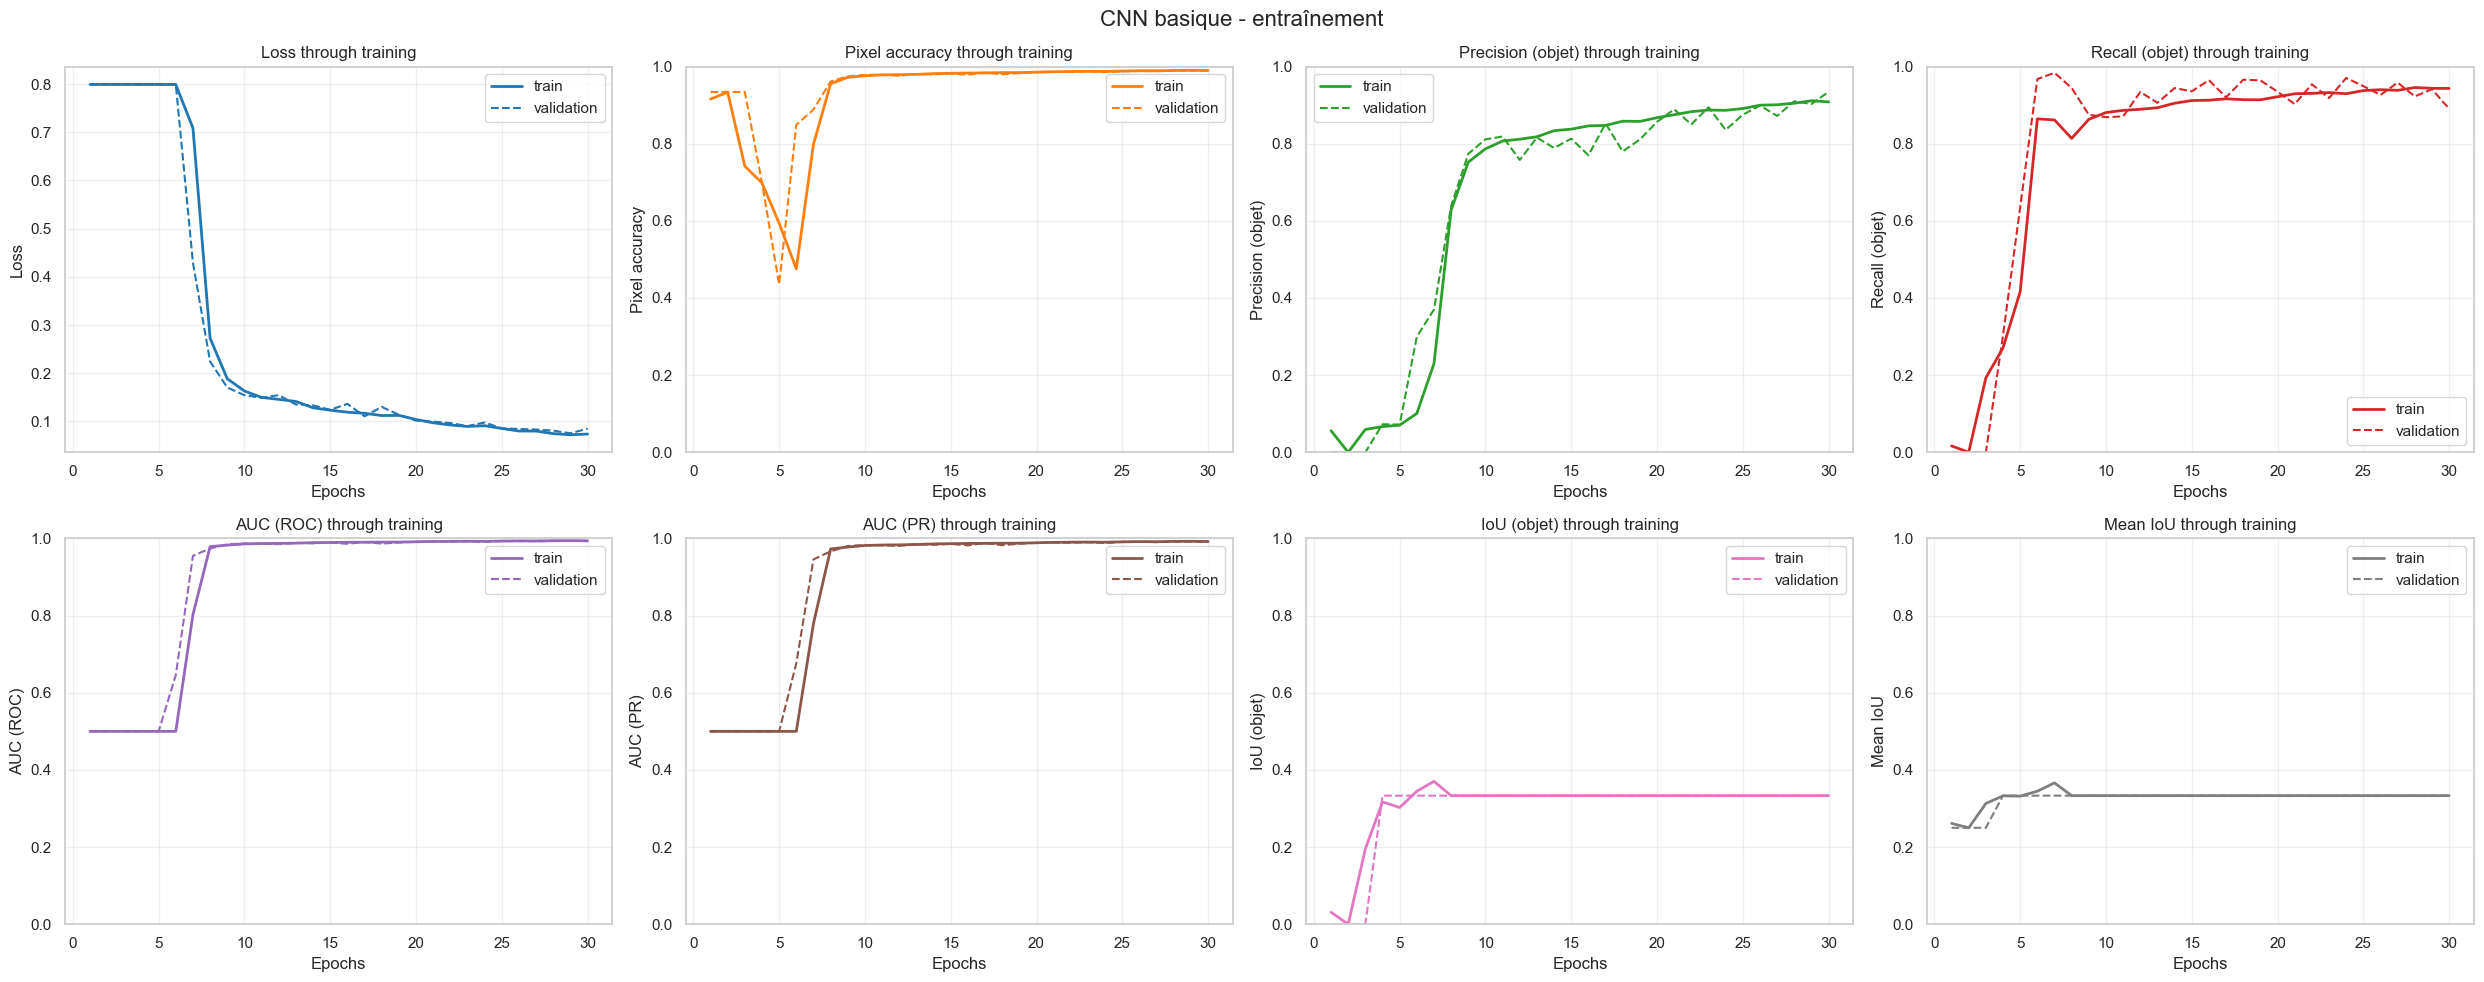

In [38]:
history_df_basic_cnn = pd.DataFrame(history_basic_cnn.history)
epochs = range(1, len(history_df_basic_cnn) + 1)  # robuste si early stopping

metrics = [
    "loss", "accuracy", "precision", "recall",
    "auc", "auc_pr", "iou_fg", "mean_iou",
]
titles = {
    "loss": "Loss",
    "accuracy": "Pixel accuracy",
    "precision": "Precision (objet)",
    "recall": "Recall (objet)",
    "auc": "AUC (ROC)",
    "auc_pr": "AUC (PR)",
    "iou_fg": "IoU (objet)",
    "mean_iou": "Mean IoU",
}

figure, axes = plt.subplots(2, 4, figsize=(25, 10))
palette = sns.color_palette("tab10", n_colors=len(metrics))

for index, (metric_name, axis) in enumerate(zip(metrics, axes.flat)):
    if metric_name not in history_df_basic_cnn.columns:
        axis.set_visible(False)  # métrique absente de l'historique
        continue

    color = palette[index]
    axis.plot(epochs, history_df_basic_cnn[metric_name], lw=2, color=color, label="train")
    if "val_" + metric_name in history_df_basic_cnn.columns:
        axis.plot(epochs, history_df_basic_cnn["val_" + metric_name], ls="--", color=color, label="validation")

    if metric_name != "loss":
        axis.set_ylim(0, 1)
    axis.set_ylabel(titles[metric_name])
    axis.set_xlabel("Epochs")
    axis.set_title("%s through training" % titles[metric_name])
    axis.grid(alpha=0.3)
    axis.legend()

plt.suptitle("CNN basique - entraînement", fontsize=16)
plt.tight_layout()
plt.show()

In [39]:
display(history_df_basic_cnn)

,loss,accuracy,precision,recall,auc,auc_pr,iou_fg,mean_iou,val_loss,val_accuracy,val_precision,val_recall,val_auc,val_auc_pr,val_iou_fg,val_mean_iou
0,0.799172,0.915659,0.055998,0.016513,0.500000,0.500000,0.031250,0.261527,0.800134,0.934044,0.000000,0.000000,0.500000,0.500000,0.000000,0.250000
1,0.799172,0.933266,0.000000,0.000000,0.500000,0.500000,0.000000,0.250000,0.800134,0.934044,0.000000,0.000000,0.500000,0.500000,0.000000,0.250000
2,0.799173,0.741629,0.059236,0.192966,0.500000,0.500000,0.195122,0.313078,0.800134,0.934044,0.000000,0.000000,0.500000,0.500000,0.000000,0.250000
3,0.799172,0.698296,0.066687,0.270891,0.500000,0.500000,0.317073,0.332955,0.800134,0.698747,0.072733,0.303546,0.500000,0.500000,0.333333,0.333333
4,0.799170,0.593732,0.070351,0.416498,0.500000,0.500000,0.302632,0.332039,0.800131,0.434927,0.071889,0.635349,0.500000,0.500000,0.333333,0.333333
5,0.799107,0.475447,0.100640,0.864381,0.500000,0.500000,0.344828,0.344828,0.799572,0.848759,0.299707,0.967437,0.645933,0.676420,0.333333,0.333333
6,0.708705,0.798319,0.230026,0.861474,0.802583,0.779477,0.370370,0.366435,0.429185,0.888461,0.370017,0.983698,0.955028,0.945725,0.333333,0.333333
7,0.272590,0.955401,0.627980,0.813778,0.978708,0.972874,0.333333,0.333333,0.224177,0.961071,0.638520,0.944420,0.973949,0.966482,0.333333,0.333333
8,0.188468,0.971889,0.752199,0.863086,0.982743,0.977716,0.333333,0.333333,0.170336,0.974881,0.773788,0.874923,0.984807,0.980358,0.333333,0.333333
9,0.163105,0.976089,0.786605,0.880592,0.985887,0.981750,0.333333,0.333333,0.154386,0.978006,0.811211,0.868706,0.987021,0.983204,0.333333,0.333333


In [40]:
y_test_basic_cnn = tf.one_hot(y_test[..., 0], depth=2)
score_basic_cnn = basic_cnn.evaluate(X_test, y_test_basic_cnn, batch_size=BATCH_SIZE, return_dict=True)

# Dice (= F1 pixel) déduit de la précision et du recall de la classe objet
dice_basic_cnn = 2 * score_basic_cnn["precision"] * score_basic_cnn["recall"] / (score_basic_cnn["precision"] + score_basic_cnn["recall"] + 1e-8)

df_score_basic_cnn = pd.DataFrame(
    {
        "Métrique": [
            "Loss",
            "Accuracy",
            "Precision (objet)",
            "Recall (objet)",
            "Dice / F1 (objet)",
            "IoU (objet)",
            "Mean IoU",
            "AUC (ROC)",
            "AUC (PR)",
        ],
        "Valeur": [
            score_basic_cnn["loss"],
            score_basic_cnn["accuracy"],
            score_basic_cnn["precision"],
            score_basic_cnn["recall"],
            dice_unet_original,
            score_basic_cnn["iou_fg"],
            score_basic_cnn["mean_iou"],
            score_basic_cnn["auc"],
            score_basic_cnn["auc_pr"],
        ],
    }
).set_index("Métrique")

display(df_score_basic_cnn.style.format("{:.4f}"))

10/10 [==============================] - 1s 125ms/step - loss: 0.0864 - accuracy: 0.9887 - precision: 0.9354 - recall: 0.8894 - auc: 0.9930 - auc_pr: 0.9909 - iou_fg: 0.3333 - mean_iou: 0.3333


,Valeur
Métrique,
Loss,0.0864
Accuracy,0.9887
Precision (objet),0.9354
Recall (objet),0.8894
Dice / F1 (objet),0.9450
IoU (objet),0.3333
Mean IoU,0.3333
AUC (ROC),0.9930
AUC (PR),0.9909


## 7. Méthodes de machine learning

### 7.1 Création des caractéristiques

In [41]:
#Filtre gaussien
def gauss(img, sigma):
    return ndi.gaussian_filter(img, sigma, mode="reflect")

# Hyperparamètres des features
GRAY_SIGMAS = (2.5, 5, 10)            # paramètre sigma pour le filtre gaussien d'une image en gris (valeurs du document)
GABOR_FREQS = (0.05, 0.1, 0.2)        # 3 échelles de Gabor
GABOR_THETAS = [k * np.pi / 6 for k in range(6)]   # 6 directions de Gabor
GRAD_RADIUS = 1                       # jusqu'où on regarde autour du pixel pour le gradient (1 -> fenêtre 3x3)
#TEXTON_SIGMAS = (5, 10, 20)           # lissage des textons (valeurs du document)


# rogner l'image afin que l'entrée et la sortie soient de même taille (388x388)
def crop(img):
    return img[PAD_SIZE:-PAD_SIZE, PAD_SIZE:-PAD_SIZE]

# Calcul des gradients
def gradient_features(img, radius=1):
    img = np.asarray(img, dtype=np.float32)
    size = 2 * radius + 1

    # 1) Gradient en chaque pixel (Sobel) : force du contour
    gx = ndi.sobel(img, axis=1)          # image des gradient de changement gauche -> droite
    gy = ndi.sobel(img, axis=0)          # image des gradient de changement haut -> bas
    g = np.hypot(gx, gy)                 # sqrt(gx² + gy²), image des gradient de magnitude du gradient

    # 2) Statistiques du gradient dans la fenêtre autour du pixel
    g_mean = ndi.uniform_filter(g, size=size)      # image des gradient de gradient moyen autour
    g_min = ndi.minimum_filter(g, size=size)       # image des gradient de gradient minimum autour
    g_max = ndi.maximum_filter(g, size=size)       # image des gradient de gradient maximum autour

    return [
        (g, "grad_mag"),
        (g_mean, f"grad_mean_r{radius}"),
        (g_min, f"grad_min_r{radius}"),
        (g_max, f"grad_max_r{radius}"),
    ]


# Création des 32 features
def compute_features(img):
    """img : (572, 572) float32. Renvoie ((388, 388, F) float32, liste des noms)."""
    img = np.ascontiguousarray(img, dtype=np.float32)
    feats, names = [], []

    def add(carte_feature, name):
        feats.append(crop(carte_feature).astype(np.float32))
        names.append(name)

    # Niveau de gris -- 10 features
    add(img, "gray")
    for s in GRAY_SIGMAS:
        m = gauss(img, s)
        m2 = gauss(img * img, s)
        add(m, f"gray_mean_s{s}")                               # moyenne
        add(np.abs(img - m), f"gray_absdiff_s{s}")              # différence de moyenne
        add(np.maximum(m2 - m * m, 0), f"gray_var_s{s}")        # variance


    # Contour : gradient -- 4 features
    for carte, nom in gradient_features(img, radius=GRAD_RADIUS):
        add(carte, nom)


    # Texture : filtres de Gabor (6 directions x 3 échelles) -- 18 features
    gabor = []
    for f in GABOR_FREQS:
        for th in GABOR_THETAS:
            resp = np.abs(fftconvolve(img, gabor_kernel(f, theta=th), mode="same")).astype(np.float32)
            gabor.append(resp)
            add(resp, f"tex_gabor_f{f}_t{int(round(np.degrees(th)))}")


    return np.stack(feats, axis=-1), names


t0 = time.time()
_F, FEATURE_NAMES = compute_features(X_train[0, ..., 0])
print(f"{len(FEATURE_NAMES)} features | forme {_F.shape} | {time.time() - t0:.1f}s par image")

32 features | forme (388, 388, 32) | 0.7s par image


In [42]:
N_PER_IMAGE = 40000       # pixels échantillonnés par image d'entraînement, sinon trop couteux

def sample_pixels(F, mask, w, n, rng):
    H, L, nf = F.shape

    # Les pixels avec un poids élevé ont plus de chances d'être choisis afin de favoriser l'apprentissage des contours
    weights = w.reshape(-1)
    probabilities = weights / weights.sum()

    idx = rng.choice(H*L, n, replace=False, p=probabilities)

    X = F.reshape(-1, nf)[idx]
    y = mask.reshape(-1)[idx]

    return X, y


# Train : features calculées puis échantillonnées (image par image)
t0 = time.time()

rng = np.random.default_rng(RANDOM_STATE)
Xs, ys = [], []

for i, item in enumerate(tqdm(train_items, desc="Features train")):
    F, _ = compute_features(item["img_p"])
    a, b = sample_pixels(F, item["mask"], item["w"], N_PER_IMAGE, rng)
    Xs.append(a); ys.append(b)

Xp_train = np.concatenate(Xs)
yp_train = np.concatenate(ys).astype(np.uint8)

t_feat_train = time.time() - t0


# Val / test : features
def extract_all(X_imgs, desc):
    out = np.zeros((len(X_imgs), OUTPUT_SIZE, OUTPUT_SIZE, len(FEATURE_NAMES)), np.float16)
    for i in tqdm(range(len(X_imgs)), desc=desc):
        out[i] = compute_features(X_imgs[i, :, :, 0])[0].astype(np.float16)
    return out


F_val = extract_all(X_val_s, "Features val")
F_test = extract_all(X_test_s, "Features test")

# échantillon de pixels de validation (early stopping XGBoost)
rng_v = np.random.default_rng(RANDOM_STATE)
v = [sample_pixels(F_val[i].astype(np.float32), val_items[i]["mask"], val_items[i]["w"], N_PER_IMAGE, rng_v) for i in range(len(F_val))]   # <--
Xp_val = np.concatenate([a for a, _ in v])
yp_val = np.concatenate([b for _, b in v]).astype(np.uint8)

print(f"Train pixels : {Xp_train.shape} | % cellule : {yp_train.mean():.3f}")
print(f"Val pixels   : {Xp_val.shape} | % cellule : {yp_val.mean():.3f}")
print(f"Extraction des features (train) : {t_feat_train:.0f}s")

Features test: 100%|██████████| 46/46 [00:30<00:00,  1.51it/s]


Train pixels : (5880000, 32) | % cellule : 0.237
Val pixels   : (1480000, 32) | % cellule : 0.236
Extraction des features (train) : 101s


### 7.2 Random Forest

In [43]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight=None,           # pas de pondération : probabilités mieux calibrées (le seuil est ajusté sur la validation)
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
t0 = time.time()
rf.fit(Xp_train, yp_train)
train_time = {"RandomForest": time.time() - t0}
print(f"Random Forest entraîné en {train_time['RandomForest']:.0f}s")

Random Forest entraîné en 1713s


### 7.3 XGBoost

In [44]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=600,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0.0,
    tree_method="hist",
    eval_metric="auc",
    early_stopping_rounds=30,        # arrêt automatique sur la validation
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
t0 = time.time()
xgb.fit(Xp_train, yp_train, eval_set=[(Xp_val, yp_val)], verbose=50)
train_time = {"RandomForest": time.time() - t0}
train_time["XGBoost"] = time.time() - t0
print(f"XGBoost entraîné en {train_time['XGBoost']:.0f}s | meilleure itération : {xgb.best_iteration}")

[0]	validation_0-auc:0.98583
[50]	validation_0-auc:0.99270
[100]	validation_0-auc:0.99395
[150]	validation_0-auc:0.99470
[200]	validation_0-auc:0.99514
[250]	validation_0-auc:0.99544
[300]	validation_0-auc:0.99568
[350]	validation_0-auc:0.99585
[400]	validation_0-auc:0.99601
[450]	validation_0-auc:0.99614
[500]	validation_0-auc:0.99624
[550]	validation_0-auc:0.99634
[599]	validation_0-auc:0.99641
XGBoost entraîné en 397s | meilleure itération : 599


## 8. DeepLabV3+
méthode encoder-decoder différente de Unet utilisant convolution dilatée

In [45]:
### version sans convolution séparable (plus couteux en calcul)
def convolution_block2(
    block_input,
    num_filters=256,
    kernel_size=3,
    dilation_rate=1,
    use_bias=False,
):
    x = keras.layers.Conv2D(
        num_filters,
        kernel_size=kernel_size,
        dilation_rate=dilation_rate,
        padding="same",
        use_bias=use_bias,
        kernel_initializer=keras.initializers.HeNormal(),
    )(block_input)
    x = keras.layers.BatchNormalization()(x)
    return keras.activations.relu(x)

### Utilisation de convolutions séparables pour réduire drastiquement le nombre de paramètres
def convolution_block(
    block_input,
    num_filters=256,
    kernel_size=3,
    dilation_rate=1,
    use_bias=False,
):
    # Convolutions 3x3 : version séparable
    if kernel_size == 3:
        x = keras.layers.SeparableConv2D(
            filters=num_filters,
            kernel_size=kernel_size,
            dilation_rate=dilation_rate,
            padding="same",
            use_bias=use_bias,
            depthwise_initializer=keras.initializers.HeNormal(),
            pointwise_initializer=keras.initializers.HeNormal(),
        )(block_input)

    # Convolutions 1x1 : version classique
    else:
        x = keras.layers.Conv2D(
            filters=num_filters,
            kernel_size=kernel_size,
            dilation_rate=dilation_rate,
            padding="same",
            use_bias=use_bias,
            kernel_initializer=keras.initializers.HeNormal(),
        )(block_input)

    x = keras.layers.BatchNormalization()(x)
    return keras.activations.relu(x)


def DilatedSpatialPyramidPooling(dspp_input):
    dims = dspp_input.shape     # (batch, height, width, channels)

    # La partie image pool (avg pool + conv + upsample)
    x = keras.layers.AveragePooling2D(pool_size=(dims[-3], dims[-2]))(dspp_input)   # dims[-3] = dims[1] = height
    x = convolution_block(x, kernel_size=1, use_bias=True)
    out_pool = keras.layers.UpSampling2D(
        size=(dims[-3] // x.shape[1], dims[-2] // x.shape[2]),
        interpolation="bilinear",
    )(x)

    # Dilation rate correspond a l'écart entre les pixels du kernel (taux elevé = écart grand)
    out_1 = convolution_block(dspp_input, kernel_size=1, dilation_rate=1)
    out_6 = convolution_block(dspp_input, kernel_size=3, dilation_rate=6)
    out_12 = convolution_block(dspp_input, kernel_size=3, dilation_rate=12)
    out_18 = convolution_block(dspp_input, kernel_size=3, dilation_rate=18)

    x = keras.layers.Concatenate(axis=-1)([out_pool, out_1, out_6, out_12, out_18])
    output = convolution_block(x, kernel_size=1)
    return output



def get_deeplabv3_plus(image_size=572, num_classes=1):
    model_input = keras.Input(shape=(image_size, image_size, 1))
    ### Comparaison perds en sens avec ce pre-entrainement peut etre utiliser un resnet a nous
    resnet50 = keras.applications.ResNet50(
        weights=None, include_top=False, input_tensor=model_input
    )
    x = resnet50.get_layer("conv4_block6_2_relu").output
    x = DilatedSpatialPyramidPooling(x)

    # partie du décodeur venant de la pyramide
    input_a = keras.layers.UpSampling2D(
        size=(image_size // 4 // x.shape[1], image_size // 4 // x.shape[2]),
        interpolation="bilinear",
    )(x)

    # partie du décodeur venant de la couche intermédiaire du resnet50, num_filters=48 pour ne pas diminuer son impact sur la segmtnation
    input_b = resnet50.get_layer("conv2_block3_2_relu").output
    input_b = convolution_block(input_b, num_filters=48, kernel_size=1)
    input_a = keras.layers.Resizing(input_b.shape[1], input_b.shape[2])(input_a)


    x = keras.layers.Concatenate(axis=-1)([input_a, input_b])
    #Une ou deux convolutions, à tester selon les performances
    x = convolution_block(x)
    x = convolution_block(x)
    x = keras.layers.UpSampling2D(
        size=(image_size // x.shape[1], image_size // x.shape[2]),
        interpolation="bilinear",
    )(x)
    ## Version avec sigmoid pour la segmentation binaire, et avec softmax également possible mais potentiellement moins de sens pour binaire
    x = keras.layers.Resizing(572, 572)(x)
    x = keras.layers.Cropping2D(((92, 92), (92, 92)))(x)
    model_output = keras.layers.Conv2D(num_classes, kernel_size=(1, 1), padding="same", activation="sigmoid")(x)
    #model_output = keras.layers.Conv2D(num_classes, kernel_size=(1, 1), padding="same")(x)
    return keras.Model(inputs=model_input, outputs=model_output)


deeplabv3_plus = get_deeplabv3_plus(image_size=572, num_classes=1)
deeplabv3_plus.summary()


deeplabv3_plus.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy"), keras.metrics.Recall(name="recall")],
)

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_3 (InputLayer)           [(None, 572, 572, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv1_pad (ZeroPadding2D)      (None, 578, 578, 1)  0           ['input_3[0][0]']                
                                                                                                  
 conv1_conv (Conv2D)            (None, 286, 286, 64  3200        ['conv1_pad[0][0]']              
                                )                                                                 
                                                                                              

In [52]:
early_stopping_deeplabv3_plus = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

y_train_deeplabv3_plus = y_train[..., 0:1].astype("float32")
y_val_deeplabv3_plus = y_val[..., 0:1].astype("float32")

optimizer_deeplabv3_plus = keras.optimizers.Adam(learning_rate=1e-3)
deeplabv3_plus.compile(
    optimizer=optimizer_deeplabv3_plus,
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc"),
        keras.metrics.AUC(curve="PR", name="auc_pr"),
        keras.metrics.BinaryIoU(name="iou_fg"),
        keras.metrics.MeanIoU(num_classes=2, name="mean_iou")

    ],
)

history_deeplabv3_plus = deeplabv3_plus.fit(
    X_train,
    y_train_deeplabv3_plus,
    epochs=N_EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val_deeplabv3_plus),
    callbacks=[early_stopping_deeplabv3_plus],
)

Epoch 1/30
30/30 [==============================] - 52s 2s/step - loss: 0.0430 - accuracy: 0.9875 - precision: 0.9082 - recall: 0.9043 - auc: 0.9890 - auc_pr: 0.9476 - iou_fg: 0.3333 - mean_iou: 0.3419 - val_loss: 28.1562 - val_accuracy: 0.9284 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_auc: 0.4966 - val_auc_pr: 0.0642 - val_iou_fg: 0.1667 - val_mean_iou: 0.1667
Epoch 2/30
30/30 [==============================] - 45s 2s/step - loss: 0.0148 - accuracy: 0.9941 - precision: 0.9524 - recall: 0.9599 - auc: 0.9993 - auc_pr: 0.9919 - iou_fg: 0.3333 - mean_iou: 0.2500 - val_loss: 44.4402 - val_accuracy: 0.0708 - val_precision: 0.0641 - val_recall: 0.9628 - val_auc: 0.4771 - val_auc_pr: 0.0632 - val_iou_fg: 0.3330 - val_mean_iou: 0.3333
Epoch 3/30
30/30 [==============================] - 44s 1s/step - loss: 0.0121 - accuracy: 0.9951 - precision: 0.9626 - recall: 0.9638 - auc: 0.9996 - auc_pr: 0.9949 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.5512 - val_accuracy: 0.7686 - 

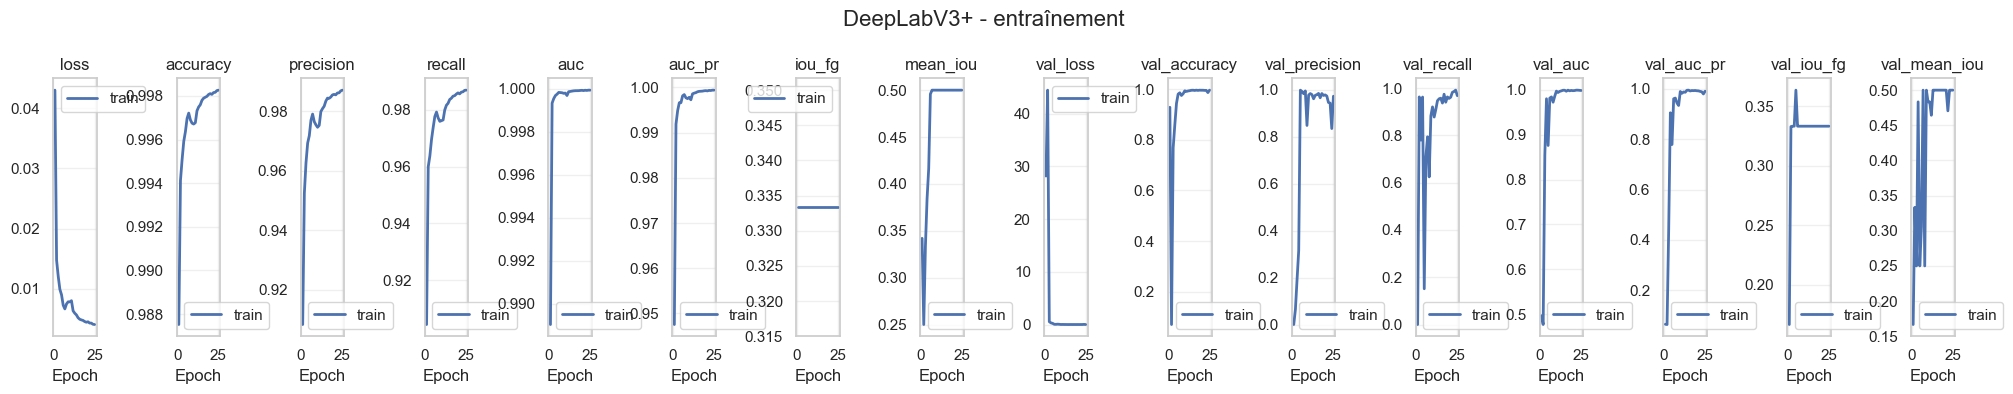

In [53]:
history_df_deeplabv3_plus = pd.DataFrame(history_deeplabv3_plus.history)
epochs = range(1, len(history_df_deeplabv3_plus) + 1)

figure, axes = plt.subplots(1, len(history_df_deeplabv3_plus.columns), figsize=(20, 4))
if not hasattr(axes, "__iter__"):
    axes = [axes]

for axis, metric_name in zip(axes, history_df_deeplabv3_plus.columns):
    axis.plot(epochs, history_df_deeplabv3_plus[metric_name], lw=2, label="train")
    axis.set_title(metric_name)
    axis.set_xlabel("Epoch")
    axis.grid(alpha=0.3)
    axis.legend()

plt.suptitle("DeepLabV3+ - entraînement", fontsize=16)
plt.tight_layout()
plt.show()

In [54]:
display(history_df_deeplabv3_plus)

,loss,accuracy,precision,recall,auc,auc_pr,iou_fg,mean_iou,val_loss,val_accuracy,val_precision,val_recall,val_auc,val_auc_pr,val_iou_fg,val_mean_iou
0,0.042971,0.987519,0.908234,0.904342,0.989036,0.947558,0.333333,0.341935,28.156193,0.928389,0.000000,0.000000,0.496594,0.064228,0.166667,0.166667
1,0.014770,0.994123,0.952391,0.959927,0.999338,0.991888,0.333333,0.250000,44.440182,0.070786,0.064125,0.962774,0.477100,0.063174,0.333004,0.333333
2,0.012076,0.995088,0.962626,0.963812,0.999552,0.994867,0.333333,0.333333,0.551207,0.768625,0.191769,0.780204,0.854371,0.445530,0.333333,0.250000
3,0.009917,0.995918,0.969242,0.969599,0.999690,0.996617,0.333333,0.384146,0.321864,0.859648,0.315232,0.962224,0.980120,0.905355,0.333333,0.483333
4,0.009023,0.996365,0.971745,0.973844,0.999755,0.996626,0.333333,0.416667,0.234552,0.944002,0.997774,0.151309,0.876022,0.779192,0.363636,0.250000
5,0.007302,0.996969,0.976929,0.977667,0.999837,0.998142,0.333333,0.495763,0.060192,0.980504,0.991895,0.710211,0.981559,0.961145,0.333333,0.305556
6,0.006678,0.997212,0.978998,0.979236,0.999829,0.998415,0.333333,0.500000,0.046640,0.985491,0.982642,0.794045,0.984207,0.963847,0.333333,0.500000
7,0.007499,0.996905,0.976455,0.977183,0.999821,0.997701,0.333333,0.500000,0.080272,0.975001,0.994434,0.624463,0.972452,0.944175,0.333333,0.250000
8,0.007857,0.996752,0.975389,0.975953,0.999794,0.997520,0.333333,0.500000,0.056010,0.981767,0.847513,0.882294,0.985789,0.934307,0.333333,0.500000
9,0.007846,0.996711,0.974567,0.976189,0.999804,0.997813,0.333333,0.500000,0.017670,0.993319,0.976904,0.920472,0.997165,0.989992,0.333333,0.483333


In [56]:
y_test_deeplabv3_plus = y_test[..., 0].astype("float32")
y_test_deeplabv3_plus = y_test[..., 0:1].astype("float32")

score_deeplabv3_plus = deeplabv3_plus.evaluate(
    X_test,
    y_test_deeplabv3_plus,
    batch_size=BATCH_SIZE,
    return_dict=True
)

df_score_deeplabv3_plus = pd.DataFrame(
    {
        "Métrique": list(score_deeplabv3_plus.keys()),
        "Valeur": list(score_deeplabv3_plus.values()),
    }
).set_index("Métrique")

display(df_score_deeplabv3_plus.style.format("{:.4f}"))

10/10 [==============================] - 2s 238ms/step - loss: 0.0123 - accuracy: 0.9956 - precision: 0.9747 - recall: 0.9581 - auc: 0.9991 - auc_pr: 0.9913 - iou_fg: 0.3333 - mean_iou: 0.4762


,Valeur
Métrique,
loss,0.0123
accuracy,0.9956
precision,0.9747
recall,0.9581
auc,0.9991
auc_pr,0.9913
iou_fg,0.3333
mean_iou,0.4762


## 9. Comparaison et analyse

In [61]:
score_models = {
    "U-Net original": score_unet_original,
    "U-Net simplifié": score_unet_simplified,
    "U-Net padding": score_unet_padding,
    "ResNet-50": score_resnet50,
    "CNN basique": score_basic_cnn,
    "DeepLabV3+": score_deeplabv3_plus,
}

comparison_df = pd.DataFrame({
    "Modèle": list(score_models.keys()),
    "Loss": [scores["loss"] for scores in score_models.values()],
    "Accuracy": [scores["accuracy"] for scores in score_models.values()],
    "Precision": [scores["precision"] for scores in score_models.values()],
    "Recall": [scores["recall"] for scores in score_models.values()],
    "Dice / F1": [add_dice(scores) for scores in score_models.values()],
    "IoU (objet)": [scores["iou_fg"] for scores in score_models.values()],
    "Mean IoU": [scores["mean_iou"] for scores in score_models.values()],
    "AUC (ROC)": [scores["auc"] for scores in score_models.values()],
    "AUC (PR)": [scores["auc_pr"] for scores in score_models.values()],
}).set_index("Modèle")

display(
    comparison_df.style
    .format("{:.4f}")
    .highlight_min(subset=["Loss"], color="rey")
    .highlight_max(subset=comparison_df.columns.drop("Loss"), color="grey")
)

,Loss,Accuracy,Precision,Recall,Dice / F1,IoU (objet),Mean IoU,AUC (ROC),AUC (PR)
Modèle,,,,,,,,,
U-Net original,0.0543,0.9927,0.9339,0.9565,0.9450,0.3333,0.3333,0.9964,0.9954
U-Net simplifié,0.8032,0.9346,0.0000,0.0000,0.0000,0.0000,0.2500,0.9446,0.9193
U-Net padding,0.1022,0.9868,0.9269,0.8664,0.8956,0.3333,0.3333,0.9943,0.9926
ResNet-50,0.8075,0.9346,0.0000,0.0000,0.0000,0.0000,0.2500,0.9302,0.9114
CNN basique,0.0864,0.9887,0.9354,0.8894,0.9118,0.3333,0.3333,0.9930,0.9909
DeepLabV3+,0.0123,0.9956,0.9747,0.9581,0.9664,0.3333,0.4762,0.9991,0.9913


In [60]:
from sklearn.metrics import (log_loss, accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, average_precision_score, jaccard_score)

def evaluate(model, X, y, seuil = 0.5):
    """Renvoie un dictionnaire de métriques pour le modèle donné sur les données X, y."""
    y_proba = model.predict_proba(X)[:, 1]  # probabilité de la classe positive
    y_pred = (y_proba >= seuil).astype(np.uint8)

    return {
        "loss": log_loss(y, y_proba),
        "accuracy": accuracy_score(y, y_pred),
        "precision": precision_score(y, y_pred),
        "recall": recall_score(y, y_pred),
        "f1": f1_score(y, y_pred),
        "auc_roc": roc_auc_score(y, y_proba),
        "auc_pr": average_precision_score(y, y_proba),
        "iou": jaccard_score(y, y_pred),
    }

resultat = pd.DataFrame({   
    "RandomForest": evaluate(rf, Xp_val, yp_val),
    "XGBoost": evaluate(xgb, Xp_val, yp_val),
    }
).round(4).T.rename_axis("Métrique")

display(resultat)

,loss,accuracy,precision,recall,f1,auc_roc,auc_pr,iou
Métrique,,,,,,,,
RandomForest,0.0799,0.9704,0.9184,0.9596,0.9386,0.9946,0.9793,0.8842
XGBoost,0.0622,0.9767,0.9429,0.9591,0.9510,0.9964,0.9866,0.9065
